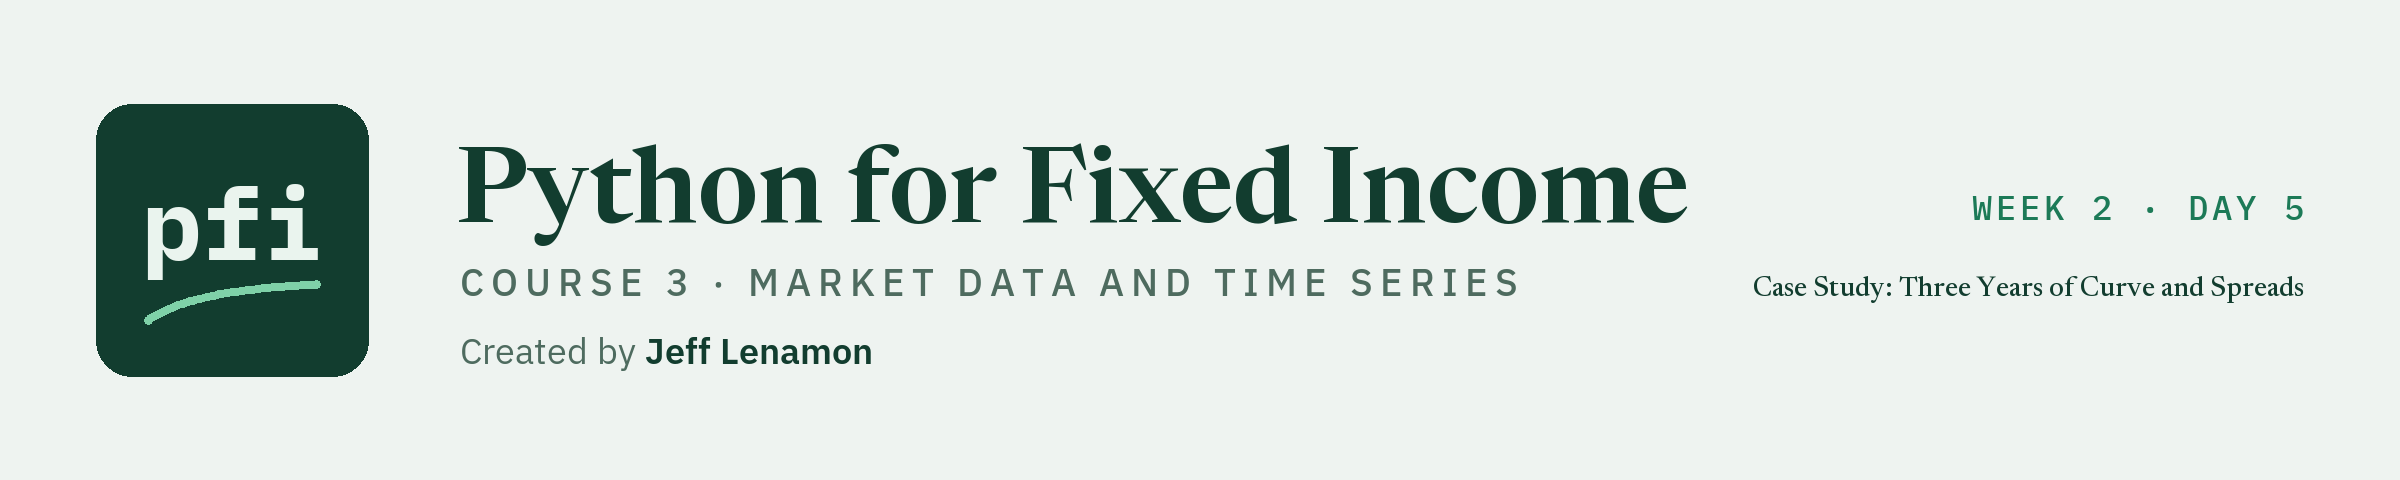

# Case Study: Three Years of Curve and Spreads

Week 2, Day 5. Week 2 ends with one function and one real job: summary_table, every measure of the week as of one date, built only from rows on or before that date; then three years of the Treasury curve and the course's synthetic spreads, described from first row to last.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course03_market_data/week2/day5/10_case_study_three_years_of_curve_and_spreads.ipynb)

Days 6 to 9 gave you the measures a market screen is made of: changes in bp, rolling volatility, z-scores, percentile ranks, slopes, and butterflies. Each one is a column computed over a whole series. A desk reads them differently: **one date, one row per series, every measure side by side.** Today builds that row, and then uses it.

The day has two halves.

**Hands-on, sections 10.1 and 10.2.**

1. Add `summary_table` to your module, the 22nd function: the level, the one-day, one-week, and one-month changes in bp, the z-score, and the percentile rank of each series, as of one date.
2. Check it against the Excel reference rows, and prove that it reads only rows on or before its as-of date.

**Case study, sections 10.3 to 10.11.** Three years of the Treasury curve and the course's synthetic spreads, from 2023-10-03 to 2026-10-02: levels, changes, volatility, where each series sits in its own history, the shape of the curve, and the two spreads. Six Predict questions, a four-panel chart, and written observations. Every observation says what the data was. None says why it moved or what comes next.

**The spreads are synthetic.** `course3_synthetic_spreads.csv` was invented by the course's data generator. It is not ICE, not Moody's, and not any index, and it describes no real market. Every table and chart of it below says so.

Git closes the week with a `week2` tag and compares it with `week1`.

The setup cell is the same as all week. The next cells write `bondmath.py`, and `marketdata.py` and `test_marketdata.py` as they stood at the end of day 9.

Q. Set up today's work folder and copy today's four data files into it.

## Before you start: install the libraries

Run this cell first. It checks that every library this course pins in its `requirements.txt` is installed and installs only what is missing, so it finishes in a second on a machine set up from the repo's `requirements.txt` and does the installing for you in Google Colab. If it installs anything in Colab, restart the session (Runtime, Restart session) and run the notebook again from the top.

In [1]:
# install what this notebook needs: the course's pinned libraries, only those not already present
import importlib.util
import subprocess
import sys

# import name: the pinned package, from course03_market_data/requirements.txt
NEEDED = {
    "ipykernel": "ipykernel==7.4.0",
    "jinja2": "jinja2==3.1.6",
    "matplotlib": "matplotlib==3.11.2",
    "numpy": "numpy==2.5.3",
    "openpyxl": "openpyxl==3.1.5",
    "pandas": "pandas==3.0.6",
    "pytest": "pytest==9.1.1",
    "dotenv": "python-dotenv==1.2.4",
    "requests": "requests==2.34.2",
}

# a package is present when Python can find its module; the version is left as the machine has it
missing = [pin for module, pin in NEEDED.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", *missing], check=True)
    print(f"{len(NEEDED)} packages checked, {len(missing)} installed: restart the session and run again from the top")
else:
    print(f"{len(NEEDED)} packages checked, all present")

9 packages checked, all present


In [2]:
# today's setup: modules, the course data, a fresh work folder, and the constants the live cells use
import importlib
import os
import shutil
import subprocess
import sys
import tempfile
import urllib.request
from pathlib import Path

import pandas as pd

# the course's chart style, set once here so every chart in the notebook looks the same
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.figsize": (9, 5),          # width and height of a chart, in inches
    "figure.dpi": 110,                 # sharpness on screen
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    # the course greens, then a grey, for the first four lines or bars of a chart
    "axes.prop_cycle": plt.cycler(color=["#123d2f", "#1c7a57", "#7fd1a8", "#8c8c8c"]),
    "axes.grid": True,                 # light gridlines, as in an Excel chart
    "grid.color": "#dddddd",
    "axes.spines.top": False,          # no box line above or to the right of the plot
    "axes.spines.right": False,
})

# three packages a Colab runtime or a new environment may lack: stop with the line that installs the missing one
for module_name, install_name in [("pytest", "pytest"), ("requests", "requests"), ("dotenv", "python-dotenv")]:
    try:
        importlib.import_module(module_name)
    except ImportError:
        raise RuntimeError(f"{install_name} is not installed. Run  !pip install {install_name}  in a new cell, "
                           "then run this cell again.") from None
import pytest
import requests

# remember the notebook's own folder, so that running this cell again starts from the same place
if "notebook_folder" not in globals():
    notebook_folder = Path.cwd()

# 1. find the course data before moving: the repo's data folder on your machine, GitHub in Colab
RAW_DATA = "https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/"
local_data = (notebook_folder / ".." / ".." / ".." / "data").resolve()
on_github = not (local_data / "treasury_par_yields.csv").exists()
data_folder = RAW_DATA if on_github else str(local_data) + os.sep

# 2. your own key file: in your my_bondmath folder, outside every repository. Its path is never printed.
ENV_FILE = Path.home() / "projects" / "my_bondmath" / ".env"

# 3. the two constants of the live cells
NO_KEY_MESSAGE = "Live cell skipped: no FRED key was found. Every other cell runs without one."
# ICE BofA and Moody's values stay off the screen unless you set this to True, on your own machine only
SHOW_LICENSED_VALUES = False

# 4. a fresh work folder for today, in the system temp folder, outside the course repo
work = Path(tempfile.mkdtemp(prefix="pfi_course3_10_"))
os.chdir(work)

# 5. copy today's data files into the work folder
DATA_FILES = ["treasury_par_yields.csv", "course3_synthetic_spreads.csv", "course3_excel_reference.csv", "course3_fred_format_dgs10.json"]
for name in DATA_FILES:
    if on_github:
        urllib.request.urlretrieve(RAW_DATA + name, work / name)
    else:
        shutil.copy(local_data / name, work / name)

# print the folder's name only: its full path would show your user name
print(f"Work folder: {work.name}, in your temp folder")
print(f"Data files from {'GitHub' if on_github else 'the data folder of the course repo'}: {', '.join(DATA_FILES) or 'none'}")
print(f"pytest {pytest.__version__}, requests {requests.__version__}")

Work folder: pfi_course3_10_2matzu91, in your temp folder
Data files from the data folder of the course repo: treasury_par_yields.csv, course3_synthetic_spreads.csv, course3_excel_reference.csv, course3_fred_format_dgs10.json
pytest 9.1.1, requests 2.34.2


Q. Write `bondmath.py`, the reference copy of the module you finished in Course 2.

It is written into the work folder so that every notebook runs, in Colab too, whether or not you took Course 2. To use your own copy instead, run this line in a new cell after the next one:

```python
shutil.copy(Path.home() / "projects" / "my_bondmath" / "bondmath.py", work)
```

The saved outputs of this notebook always come from the reference copy.

In [3]:
%%writefile bondmath.py
"""bondmath: bond math for fixed-rate bullet bonds, checked against Excel.

Written day by day in Python for Fixed Income, Course 2: Bond Math.

Units, the same in every function:
- coupon_pct and yield_pct are annual rates in percent: 7.0 means 7 percent. Excel takes decimals (0.07).
- Prices and accrued interest are per 100 of face.
- Durations are in years, convexity in years squared, spreads in basis points.
- frequency is the number of coupons (or compounding periods) a year: 1, 2, or 4.
- basis is the day count: "30/360" (Excel basis 0) or "ACT/ACT" (Excel basis 1).
- Dates are datetime.date values.
"""
import calendar  # month lengths, used from week 2
from datetime import date  # calendar dates, used from week 2


def future_value(amount: float, rate_pct: float, years: float, frequency: int = 2) -> float:
    """Grow an amount at an annual rate compounded `frequency` times a year.

    Units: amount in dollars (or per 100 of face), rate_pct in percent, years in years.
    Convention: periodic compounding, amount x (1 + rate / frequency) ** (frequency x years).
    Excel: =FV(rate_pct/100/frequency, frequency*years, 0, -amount)
    """
    # stop on a frequency the course does not use
    if frequency not in (1, 2, 4):
        raise ValueError(f"frequency must be 1, 2, or 4, not {frequency}")
    # the rate for one period, as a decimal
    period_rate = rate_pct / 100 / frequency
    # the number of compounding periods
    periods = frequency * years
    # grow the amount over every period
    return amount * (1 + period_rate) ** periods


def present_value(amount: float, rate_pct: float, years: float, frequency: int = 2) -> float:
    """Discount an amount due in `years` at an annual rate compounded `frequency` times a year.

    Units: amount in dollars (or per 100 of face), rate_pct in percent, years in years.
    Convention: periodic compounding, amount / (1 + rate / frequency) ** (frequency x years).
    Returns a positive number for a positive amount. Excel's PV returns the same number with a
    minus sign: =-PV(rate_pct/100/frequency, frequency*years, 0, amount)
    """
    # stop on a frequency the course does not use
    if frequency not in (1, 2, 4):
        raise ValueError(f"frequency must be 1, 2, or 4, not {frequency}")
    # the rate for one period, as a decimal
    period_rate = rate_pct / 100 / frequency
    # the number of compounding periods
    periods = frequency * years
    # discount the amount over every period
    return amount / (1 + period_rate) ** periods


def cash_flows(coupon_pct: float, years: float, frequency: int = 2) -> list[tuple[float, float]]:
    """The cash flows of a bullet bond bought on a coupon date.

    Units: coupon_pct in percent of face a year, years in years. Each cash flow is per 100 of face.
    Convention: one coupon of coupon_pct / frequency every 1 / frequency years, and 100 back with
    the last coupon. Returns a list of (time in years, cash flow) pairs, earliest first.
    Raises ValueError unless years x frequency is a whole number of periods.
    """
    # stop on a frequency the course does not use
    if frequency not in (1, 2, 4):
        raise ValueError(f"frequency must be 1, 2, or 4, not {frequency}")
    # count the coupon periods and check they are whole
    periods = years * frequency
    if periods <= 0 or abs(periods - round(periods)) > 1e-9:
        raise ValueError(f"{years} years is not a whole number of periods at frequency {frequency}")
    periods = round(periods)
    # each coupon is the annual coupon split into equal parts
    coupon = coupon_pct / frequency
    flows = []
    for k in range(1, periods + 1):
        # the time of payment k, in years
        time_years = k / frequency
        # the last payment also returns the face of 100
        amount = coupon + 100 if k == periods else coupon
        flows.append((time_years, amount))
    return flows


def price_from_yield(coupon_pct: float, yield_pct: float, years: float, frequency: int = 2) -> float:
    """Price of a bullet bond on a coupon date, from its yield.

    Units: coupon_pct and yield_pct in percent a year, years in years, price per 100 of face.
    Convention: each cash flow is discounted at yield_pct compounded `frequency` times a year.
    On a coupon date there is no accrued interest, so this is both the clean and the dirty price.
    Excel: =-PV(yield_pct/100/frequency, frequency*years, coupon_pct/frequency, 100)
    """
    # the yield for one period, as a decimal
    period_yield = yield_pct / 100 / frequency
    price = 0.0
    for time_years, amount in cash_flows(coupon_pct, years, frequency):
        # discount each cash flow by one factor per period until it is paid
        price += amount / (1 + period_yield) ** (time_years * frequency)
    return price


def convert_yield(yield_pct: float, from_frequency: int, to_frequency: int) -> float:
    """The same yield restated at another compounding frequency.

    Units: yield_pct in percent a year; the result is in percent a year.
    Convention: both rates grow 100 to the same amount in one year.
    Excel: convert_yield(y, f, 1) is =EFFECT(y/100, f)*100, and convert_yield(y, 1, f) is =NOMINAL(y/100, f)*100.
    """
    # stop on a frequency the course does not use
    for frequency in (from_frequency, to_frequency):
        if frequency not in (1, 2, 4):
            raise ValueError(f"frequency must be 1, 2, or 4, not {frequency}")
    # how much 1 grows to in one year at the original frequency
    growth_one_year = (1 + yield_pct / 100 / from_frequency) ** from_frequency
    # the rate per period at the new frequency that gives the same growth
    period_rate = growth_one_year ** (1 / to_frequency) - 1
    # back to an annual rate in percent
    return period_rate * to_frequency * 100


def yield_from_price(coupon_pct: float, price: float, years: float, frequency: int = 2) -> float:
    """Yield of a bullet bond on a coupon date, from its price, by bisection.

    Units: coupon_pct in percent a year, price per 100 of face, years in years; the result is in percent.
    Convention: the yield, compounded `frequency` times a year, at which price_from_yield equals price.
    The search runs between -5 and 100 percent and stops when the bracket is narrower than 1e-10 percent.
    Raises ValueError if the price is outside the prices at those two yields.
    Excel: =RATE(frequency*years, coupon_pct/frequency, -price, 100)*frequency, then x 100.
    """
    # the bracket: price falls as yield rises, so the low yield gives the high price
    low_pct, high_pct = -5.0, 100.0
    highest_price = price_from_yield(coupon_pct, low_pct, years, frequency)
    lowest_price = price_from_yield(coupon_pct, high_pct, years, frequency)
    if not lowest_price <= price <= highest_price:
        raise ValueError(f"price {price} is outside {lowest_price:.6f} to {highest_price:.6f}, "
                         f"the prices at yields of {high_pct} and {low_pct} percent")
    # halve the bracket until it is narrow enough
    while high_pct - low_pct > 1e-10:
        mid_pct = (low_pct + high_pct) / 2
        if price_from_yield(coupon_pct, mid_pct, years, frequency) > price:
            # price too high at mid, so the yield is above mid
            low_pct = mid_pct
        else:
            # price too low (or equal) at mid, so the yield is at or below mid
            high_pct = mid_pct
    # the middle of the final bracket
    return (low_pct + high_pct) / 2


def add_months(d: date, months: int) -> date:
    """Move a date by whole months, keeping the day of the month where the month allows it.

    Units: d is a date, months a whole number (negative moves back).
    Convention: the day is clamped to the length of the new month, so 31 August minus 6 months is
    28 February (29 February in a leap year). Excel: =EDATE(d, months)
    """
    # count months from year 0 so the year and month come out of one division
    month_index = d.year * 12 + (d.month - 1) + months
    year, month_zero_based = divmod(month_index, 12)
    month = month_zero_based + 1
    # the number of days in the new month
    days_in_month = calendar.monthrange(year, month)[1]
    # keep the day, or use the last day of a shorter month
    return date(year, month, min(d.day, days_in_month))


def coupon_dates(settlement: date, maturity: date, frequency: int = 2) -> list[date]:
    """The previous coupon date, then every coupon date left through maturity.

    Units: dates. Convention: coupon dates are counted back from maturity in steps of 12 / frequency
    months, each one computed from maturity directly, so a 31st never drifts to the 28th. If maturity
    is the last day of its month, every coupon date is the last day of its month (Excel's rule).
    The previous coupon date is the last one on or before settlement.
    So [0] is Excel's COUPPCD, [1] is COUPNCD, and len - 1 is COUPNUM.
    """
    # stop on bad input
    if frequency not in (1, 2, 4):
        raise ValueError(f"frequency must be 1, 2, or 4, not {frequency}")
    if settlement >= maturity:
        raise ValueError(f"settlement {settlement} must be before maturity {maturity}")
    # months between coupons
    step_months = 12 // frequency
    # does the bond mature on the last day of a month?
    month_end = maturity.day == calendar.monthrange(maturity.year, maturity.month)[1]
    dates = []
    k = 0
    while True:
        # coupon k steps back from maturity, computed from maturity itself
        coupon_date = add_months(maturity, -k * step_months)
        if month_end:
            # the month-end rule: move to the last day of that month
            last_day = calendar.monthrange(coupon_date.year, coupon_date.month)[1]
            coupon_date = date(coupon_date.year, coupon_date.month, last_day)
        dates.append(coupon_date)
        # stop once we reach the previous coupon date
        if coupon_date <= settlement:
            break
        k += 1
    # earliest first
    dates.reverse()
    return dates


def days_30_360(start: date, end: date) -> int:
    """Days from start to end on the US 30/360 basis, as Excel's COUPDAYBS and YEARFRAC(..., 0) count them.

    Units: dates in, whole days out. Every month counts as 30 days and every year as 360.
    Convention, with D1 the start day and D2 the end day:
    1. If start is the last day of February, D1 = 30.
    2. If start and end are both the last day of February, D2 = 30.
    3. If D1 is 31, D1 = 30.
    4. If D2 is 31 and the start day was 30 or 31, D2 = 30. (Excel looks at the start date's own
       day here, so a start on 28 February and an end on the 31st keeps D2 = 31.)
    Days = 360 x (Y2 - Y1) + 30 x (M2 - M1) + (D2 - D1).
    Excel's DAYS360 uses different February rules and is not the same count.
    """
    d1, d2 = start.day, end.day
    start_is_feb_end = start.month == 2 and start.day == calendar.monthrange(start.year, 2)[1]
    end_is_feb_end = end.month == 2 and end.day == calendar.monthrange(end.year, 2)[1]
    # rule 1: the last day of February counts as the 30th
    if start_is_feb_end:
        d1 = 30
    # rule 2: both dates on the last day of February
    if start_is_feb_end and end_is_feb_end:
        d2 = 30
    # rule 3: a 31st start counts as the 30th
    if start.day == 31:
        d1 = 30
    # rule 4: a 31st end counts as the 30th when the start day was 30 or 31
    if end.day == 31 and start.day >= 30:
        d2 = 30
    return 360 * (end.year - start.year) + 30 * (end.month - start.month) + (d2 - d1)


def coupon_period_days(settlement: date, maturity: date, frequency: int = 2,
                       basis: str = "30/360") -> tuple[int, int, int]:
    """Day counts of the coupon period that holds settlement: (A, E, DSC).

    Units: whole days.
    A is days from the previous coupon to settlement (Excel COUPDAYBS).
    E is days in the coupon period: 360 / frequency under 30/360 (Excel COUPDAYS), and the actual days
    from the previous to the next coupon under ACT/ACT.
    DSC is days from settlement to the next coupon, as Excel's PRICE uses it: E - A under 30/360
    (this can differ from COUPDAYSNC near the end of February), actual days under ACT/ACT.
    """
    # stop on a basis the course does not use (coupon_dates checks frequency and dates)
    if basis not in ("30/360", "ACT/ACT"):
        raise ValueError(f'basis must be "30/360" or "ACT/ACT", not {basis!r}')
    # the previous and next coupon dates
    dates = coupon_dates(settlement, maturity, frequency)
    previous_coupon, next_coupon = dates[0], dates[1]
    if basis == "30/360":
        # 30/360: A by the 30/360 rules, a fixed period length, and DSC as what is left of it
        days_accrued = days_30_360(previous_coupon, settlement)
        days_in_period = 360 // frequency
        days_to_next = days_in_period - days_accrued
    else:
        # ACT/ACT: every count is actual calendar days
        days_accrued = (settlement - previous_coupon).days
        days_in_period = (next_coupon - previous_coupon).days
        days_to_next = (next_coupon - settlement).days
    return days_accrued, days_in_period, days_to_next


def accrued_interest(settlement: date, maturity: date, coupon_pct: float, frequency: int = 2,
                     basis: str = "30/360") -> float:
    """Accrued interest the buyer pays the seller, per 100 of face.

    Units: coupon_pct in percent a year; the result is per 100 of face.
    Convention: coupon_pct / frequency x A / E, with A and E from coupon_period_days.
    Excel (30/360): =100*coupon_pct/100/frequency*COUPDAYBS(...)/COUPDAYS(...)
    """
    # A and E for this settlement
    days_accrued, days_in_period, _ = coupon_period_days(settlement, maturity, frequency, basis)
    # one coupon, times the share of the period that has passed
    return coupon_pct / frequency * days_accrued / days_in_period


def price(settlement: date, maturity: date, coupon_pct: float, yield_pct: float, frequency: int = 2,
          basis: str = "30/360") -> float:
    """Clean price per 100 of face on any settlement date, as Excel's PRICE.

    Units: coupon_pct and yield_pct in percent a year; the result is a clean price per 100 of face.
    Convention: yield compounded `frequency` times a year. w = DSC / E is the part of a period left
    until the next coupon. Dirty price = sum over the N coupons left of CF_k / (1 + y/f) ** (w + k).
    In the final coupon period (N = 1) Excel uses simple interest: dirty = (100 + CF) / (1 + w x y/f).
    Clean = dirty - accrued interest.
    Excel: =PRICE(settlement, maturity, coupon_pct/100, yield_pct/100, 100, frequency, basis)
    """
    # the coupon dates and day counts (these check frequency, basis, and dates)
    dates = coupon_dates(settlement, maturity, frequency)
    days_accrued, days_in_period, days_to_next = coupon_period_days(settlement, maturity, frequency, basis)
    # coupons left, the fraction of a period to the next one, the period yield, and one coupon
    coupons_left = len(dates) - 1
    w = days_to_next / days_in_period
    period_yield = yield_pct / 100 / frequency
    coupon = coupon_pct / frequency
    if coupons_left == 1:
        # final period: simple interest on the last coupon and the face
        dirty = (100 + coupon) / (1 + w * period_yield)
    else:
        dirty = 0.0
        for k in range(coupons_left):
            # the last cash flow also returns the face
            cash_flow = coupon + 100 if k == coupons_left - 1 else coupon
            dirty += cash_flow / (1 + period_yield) ** (w + k)
    # the quote is clean: take off the accrued interest
    return dirty - accrued_interest(settlement, maturity, coupon_pct, frequency, basis)


def dirty_price(settlement: date, maturity: date, coupon_pct: float, yield_pct: float, frequency: int = 2,
                basis: str = "30/360") -> float:
    """Dirty (full, invoice) price per 100 of face: the clean price plus accrued interest.

    Units and convention as price(). Excel: =PRICE(...) + the accrued formula.
    """
    # clean price plus accrued interest
    return (price(settlement, maturity, coupon_pct, yield_pct, frequency, basis)
            + accrued_interest(settlement, maturity, coupon_pct, frequency, basis))


def yield_to_maturity(settlement: date, maturity: date, coupon_pct: float, clean_price: float,
                      frequency: int = 2, basis: str = "30/360") -> float:
    """Yield in percent from a clean price on any settlement date, by bisection, as Excel's YIELD x 100.

    Units: coupon_pct in percent a year, clean_price per 100 of face; the result is in percent a year.
    Convention: the yield at which price() equals clean_price. The search runs between -5 and 100
    percent and stops when the bracket is narrower than 1e-10 percent.
    Raises ValueError if the price is outside the prices at those two yields.
    Final coupon period: Excel's YIELD uses a formula instead of a search, with DSR, the days from
    settlement to maturity, counted by days_30_360 under 30/360 (actual days under ACT/ACT):
    yield = ((100 + CF) - dirty) / dirty x frequency x E / DSR. Under 30/360 DSR can differ from the
    E - A that PRICE uses, so in those cases YIELD does not return the yield PRICE was given.
    Excel: =YIELD(settlement, maturity, coupon_pct/100, clean_price, 100, frequency, basis)*100
    """
    # final coupon period: Excel's formula (coupon_dates and coupon_period_days check the inputs)
    if len(coupon_dates(settlement, maturity, frequency)) - 1 == 1:
        days_accrued, days_in_period, _ = coupon_period_days(settlement, maturity, frequency, basis)
        if basis == "30/360":
            days_to_maturity = days_30_360(settlement, maturity)
        else:
            days_to_maturity = (maturity - settlement).days
        coupon = coupon_pct / frequency
        # the dirty price paid, and what comes back at maturity
        paid = clean_price + coupon * days_accrued / days_in_period
        received = 100 + coupon
        # the simple return over the days left, made annual, in percent
        return (received - paid) / paid * frequency * days_in_period / days_to_maturity * 100
    # the bracket: price falls as yield rises, so the low yield gives the high price
    low_pct, high_pct = -5.0, 100.0
    highest_price = price(settlement, maturity, coupon_pct, low_pct, frequency, basis)
    lowest_price = price(settlement, maturity, coupon_pct, high_pct, frequency, basis)
    if not lowest_price <= clean_price <= highest_price:
        raise ValueError(f"price {clean_price} is outside {lowest_price:.6f} to {highest_price:.6f}, "
                         f"the prices at yields of {high_pct} and {low_pct} percent")
    # halve the bracket until it is narrow enough
    while high_pct - low_pct > 1e-10:
        mid_pct = (low_pct + high_pct) / 2
        if price(settlement, maturity, coupon_pct, mid_pct, frequency, basis) > clean_price:
            # price too high at mid, so the yield is above mid
            low_pct = mid_pct
        else:
            # price too low (or equal) at mid, so the yield is at or below mid
            high_pct = mid_pct
    # the middle of the final bracket
    return (low_pct + high_pct) / 2


def macaulay_duration(settlement: date, maturity: date, coupon_pct: float, yield_pct: float, frequency: int = 2,
                      basis: str = "30/360") -> float:
    """Macaulay duration in years: the present-value weighted average time of the cash flows.

    Units: coupon_pct and yield_pct in percent a year; the result is in years.
    Convention: t_k = (w + k) / frequency years, PV_k = CF_k / (1 + y/f) ** (w + k), and
    duration = sum of t_k x PV_k / sum of PV_k. In the final period this is DSC / E / frequency.
    Excel: =DURATION(settlement, maturity, coupon_pct/100, yield_pct/100, frequency, basis)
    """
    # the coupon dates and day counts (these check frequency, basis, and dates)
    dates = coupon_dates(settlement, maturity, frequency)
    _, days_in_period, days_to_next = coupon_period_days(settlement, maturity, frequency, basis)
    coupons_left = len(dates) - 1
    w = days_to_next / days_in_period
    period_yield = yield_pct / 100 / frequency
    coupon = coupon_pct / frequency
    total_pv, weighted_time = 0.0, 0.0
    for k in range(coupons_left):
        # each cash flow, its time in years, and its present value
        cash_flow = coupon + 100 if k == coupons_left - 1 else coupon
        time_years = (w + k) / frequency
        pv = cash_flow / (1 + period_yield) ** (w + k)
        total_pv += pv
        weighted_time += time_years * pv
    # the weighted average time
    return weighted_time / total_pv


def modified_duration(settlement: date, maturity: date, coupon_pct: float, yield_pct: float, frequency: int = 2,
                      basis: str = "30/360") -> float:
    """Modified duration in years: the percent price change for a 1-point (100 bp) change in yield.

    Units: coupon_pct and yield_pct in percent a year; the result is in years.
    Convention: Macaulay duration / (1 + y / frequency), with y = yield_pct / 100.
    Excel: =MDURATION(settlement, maturity, coupon_pct/100, yield_pct/100, frequency, basis)
    """
    # divide Macaulay duration by one plus the period yield
    period_yield = yield_pct / 100 / frequency
    return macaulay_duration(settlement, maturity, coupon_pct, yield_pct, frequency, basis) / (1 + period_yield)


def dv01(settlement: date, maturity: date, coupon_pct: float, yield_pct: float, frequency: int = 2,
         basis: str = "30/360") -> float:
    """DV01: price points per 100 of face for a 1 basis point fall in yield, positive for a long position.

    Units: coupon_pct and yield_pct in percent a year; the result is in price points per 100 of face per bp.
    Convention: modified duration x dirty price x 0.0001. Position DV01 in dollars = dv01 x par / 100.
    Excel: =MDURATION(...)*(PRICE(...)+accrued)/10000
    """
    # modified duration times the dirty price, for one basis point (0.0001 as a decimal)
    duration_years = modified_duration(settlement, maturity, coupon_pct, yield_pct, frequency, basis)
    full_price = dirty_price(settlement, maturity, coupon_pct, yield_pct, frequency, basis)
    return duration_years * full_price * 0.0001


def convexity(settlement: date, maturity: date, coupon_pct: float, yield_pct: float, frequency: int = 2,
              basis: str = "30/360") -> float:
    """Convexity in years squared, unscaled (not divided by 100 or by 2).

    Units: coupon_pct and yield_pct in percent a year; the result is in years squared.
    Convention: (1 / P) x sum of CF_k x t_k x (t_k + 1/f) / (1 + y/f) ** (f t_k + 2), where
    t_k = (w + k) / f and P is the sum of the discounted cash flows. Price change estimate:
    dP / P = -D_mod x dy + 0.5 x convexity x dy ** 2, with dy in decimal.
    Excel has no convexity function; the check is a central difference on three PRICE cells.
    """
    # the coupon dates and day counts (these check frequency, basis, and dates)
    dates = coupon_dates(settlement, maturity, frequency)
    _, days_in_period, days_to_next = coupon_period_days(settlement, maturity, frequency, basis)
    coupons_left = len(dates) - 1
    w = days_to_next / days_in_period
    period_yield = yield_pct / 100 / frequency
    coupon = coupon_pct / frequency
    total_pv, curvature = 0.0, 0.0
    for k in range(coupons_left):
        # each cash flow and its time in years
        cash_flow = coupon + 100 if k == coupons_left - 1 else coupon
        time_years = (w + k) / frequency
        # its present value, and its term in the convexity sum
        total_pv += cash_flow / (1 + period_yield) ** (w + k)
        curvature += (cash_flow * time_years * (time_years + 1 / frequency)
                      / (1 + period_yield) ** (frequency * time_years + 2))
    # divide by the price
    return curvature / total_pv


def interpolate_yield(tenor_years: float, curve_tenors: list[float], curve_yields_pct: list[float]) -> float:
    """Yield at any tenor by straight-line interpolation on a curve, flat beyond its ends.

    Units: tenors in years, yields in percent; the result is in percent.
    Convention: linear in yield against tenor between the two curve points around tenor_years. Below
    the first tenor the first yield is used, above the last tenor the last yield (as numpy.interp).
    Raises ValueError if the lists differ in length, are empty, or the tenors do not ascend.
    """
    # stop on a curve the function cannot read
    if len(curve_tenors) != len(curve_yields_pct) or len(curve_tenors) == 0:
        raise ValueError("curve_tenors and curve_yields_pct must be non-empty and the same length")
    for i in range(1, len(curve_tenors)):
        if curve_tenors[i] <= curve_tenors[i - 1]:
            raise ValueError(f"curve tenors must ascend: {curve_tenors[i - 1]} then {curve_tenors[i]}")
    # flat beyond the ends
    if tenor_years <= curve_tenors[0]:
        return curve_yields_pct[0]
    if tenor_years >= curve_tenors[-1]:
        return curve_yields_pct[-1]
    # find the two tenors around tenor_years
    i = 1
    while curve_tenors[i] < tenor_years:
        i += 1
    left_tenor, right_tenor = curve_tenors[i - 1], curve_tenors[i]
    left_yield, right_yield = curve_yields_pct[i - 1], curve_yields_pct[i]
    # move along the straight line between them
    slope = (right_yield - left_yield) / (right_tenor - left_tenor)
    return left_yield + slope * (tenor_years - left_tenor)


def years_to_maturity(settlement: date, maturity: date) -> float:
    """Years from settlement to maturity on the US 30/360 basis.

    Units: dates in, years out. Convention: days_30_360(settlement, maturity) / 360, the rule the
    holdings file used to read the curve. Excel: =YEARFRAC(settlement, maturity, 0)
    """
    # stop on dates in the wrong order
    if settlement >= maturity:
        raise ValueError(f"settlement {settlement} must be before maturity {maturity}")
    # 30/360 days over a 360-day year
    return days_30_360(settlement, maturity) / 360


def spread_to_curve_bp(yield_pct: float, years: float, curve_tenors: list[float],
                       curve_yields_pct: list[float]) -> float:
    """Yield spread over a curve at the bond's own maturity, in basis points.

    Units: yield_pct and curve yields in percent, years and tenors in years; the result is in bp.
    Convention: (yield_pct - the curve interpolated at `years`) x 100. A yield spread at the same
    maturity, not an option-adjusted spread from a spot curve.
    """
    # the curve yield at the bond's maturity
    curve_yield_pct = interpolate_yield(years, curve_tenors, curve_yields_pct)
    # the gap in percent, times 100 basis points per percent
    return (yield_pct - curve_yield_pct) * 100


def spread_duration(settlement: date, maturity: date, coupon_pct: float, yield_pct: float, frequency: int = 2,
                    basis: str = "30/360", bump_bp: float = 1.0) -> float:
    """Spread duration in years: the percent price change for a 100 bp move in the spread.

    Units: coupon_pct and yield_pct in percent a year, bump_bp in basis points; the result is in years.
    Convention: the yield is curve plus spread, so a spread move is a yield move. Central difference:
    (price at spread - bump minus price at spread + bump) / (2 x bump as a decimal) / dirty price.
    Accrued interest does not change with the spread, so clean price differences equal dirty ones.
    Excel: =(PRICE(...,yld-0.0001,...)-PRICE(...,yld+0.0001,...))/(2*0.0001)/(PRICE(...)+accrued)
    """
    # stop on a bump that cannot measure a slope
    if bump_bp <= 0:
        raise ValueError(f"bump_bp must be positive, not {bump_bp}")
    # the bump in percent (for yield_pct) and as a decimal (for the slope)
    bump_pct = bump_bp / 100
    bump_decimal = bump_bp / 10000
    # reprice with the spread down and up
    price_spread_down = price(settlement, maturity, coupon_pct, yield_pct - bump_pct, frequency, basis)
    price_spread_up = price(settlement, maturity, coupon_pct, yield_pct + bump_pct, frequency, basis)
    full_price = dirty_price(settlement, maturity, coupon_pct, yield_pct, frequency, basis)
    # the slope of price against spread, as a share of the dirty price
    return (price_spread_down - price_spread_up) / (2 * bump_decimal) / full_price


def dts(spread_duration_years: float, spread_bp: float) -> float:
    """Duration times spread (DTS), a published measure of spread risk.

    Units: spread duration in years, spread in basis points; the result is in years times bp.
    Convention: spread_duration_years x spread_bp.
    """
    # the product of the two
    return spread_duration_years * spread_bp


def weighted_average(values: list[float], weights: list[float]) -> float:
    """Weighted average of values.

    Units: the result has the units of the values; weights in any one unit (market value in dollars
    for a book). Convention: sum of value x weight / sum of weights. Excel: =SUMPRODUCT(values, weights)/SUM(weights)
    Raises ValueError if the lists differ in length or the weights sum to zero.
    """
    # stop on lists that do not line up, or weights with nothing in them
    if len(values) != len(weights):
        raise ValueError(f"{len(values)} values but {len(weights)} weights")
    total_weight = sum(weights)
    if total_weight == 0:
        raise ValueError("the weights sum to zero")
    # sum of value times weight
    total = 0.0
    for value, weight in zip(values, weights):
        total += value * weight
    return total / total_weight


def price_change_estimate(dirty_price: float, modified_duration: float, convexity: float, shift_bp: float) -> float:
    """Estimated change in price from duration and convexity, per 100 of face.

    Units: dirty_price per 100 of face, modified_duration in years, convexity in years squared,
    shift_bp in basis points (positive means yields up). The result is in price points per 100 of face.
    Convention: dirty_price x (-modified_duration x dy + 0.5 x convexity x dy ** 2), with dy = shift_bp / 10000.
    """
    # the yield change as a decimal
    dy = shift_bp / 10000
    # the duration term and the convexity term, times the price
    return dirty_price * (-modified_duration * dy + 0.5 * convexity * dy ** 2)

Writing bondmath.py


Q. Write `marketdata.py` and `test_marketdata.py` as they stand at the start of today: the reference version at the end of the last notebook.

In [4]:
%%writefile marketdata.py
"""marketdata: dated market series for fixed income, checked against Excel.

Written day by day in Python for Fixed Income, Course 3: Market Data and Time Series.

Conventions, the same in every function:
- A series has a DatetimeIndex named date: naive calendar dates (no time, no time zone), unique and ascending.
- Yields are in percent (5.29 means 5.29 percent), as Treasury and FRED publish them. Spreads are in basis points.
- Changes of yields and spreads are in basis points. Price changes are simple returns in percent.
- Windows are counted in observations (rows of the market calendar), trailing, and include the current row.
- A missing observation is NaN. It is dropped before any change or window is computed, never filled.
- A secret (an API key) is never printed, written to a file, or put in an error message.
"""
import os  # environment variables
from pathlib import Path  # file paths


def get_secret(name: str, env_file: str | Path) -> str:
    """Return a secret such as an API key, looked up in three places in a fixed order.

    Units: none; the secret is text. Convention: the first place that holds a non-empty value wins:
    1. the environment variable `name`;
    2. Colab's Secrets panel (google.colab.userdata), only when running in Colab;
    3. the .env file at `env_file`, read with dotenv.dotenv_values, which does not change os.environ.
    The value is returned and never printed. Raises RuntimeError naming the secret and the three places
    looked, never a value and never the full path of the file.
    """
    # 1. the environment: a variable set in PowerShell, or by the program that started Python
    value = os.environ.get(name)
    if value:
        return value

    # 2. Colab's Secrets panel: the import works only inside Colab
    try:
        from google.colab import userdata
    except ImportError:
        userdata = None
    if userdata is not None:
        try:
            value = userdata.get(name)
        # a secret that is not there, or one the notebook has not been given access to
        except (userdata.SecretNotFoundError, userdata.NotebookAccessError):
            value = None
        if value:
            return value

    # 3. the .env file, imported here so Colab never needs python-dotenv
    env_path = Path(env_file)
    if env_path.is_file():
        from dotenv import dotenv_values
        value = dotenv_values(env_path).get(name)
        if value:
            return value

    # nothing found: say where we looked, with the file's name only (a full path shows a user name)
    raise RuntimeError(
        f"Secret {name} not found. Looked in: the environment variable {name}, "
        f"Colab's Secrets panel, and the file {env_path.name} given as env_file."
    )


import pandas as pd  # dated series, from day 2
import requests  # HTTP, from day 2

# FRED's endpoint for the observations of one series
FRED_URL = "https://api.stlouisfed.org/fred/series/observations"


def fred_params(series_id: str, api_key: str, start: str | None = None, end: str | None = None) -> dict:
    """The query parameters for one request to FRED's series/observations endpoint.

    Units: start and end are dates as text, YYYY-MM-DD. Convention: JSON is asked for (file_type json);
    a start or end left as None is not sent, so FRED returns the series from its first or to its last date.
    Pure: builds a dict and sends nothing. The dict holds the key, so it is never printed.
    """
    # the three parameters every request needs
    params = {"series_id": series_id, "api_key": api_key, "file_type": "json"}
    # the optional date range
    if start is not None:
        params["observation_start"] = start
    if end is not None:
        params["observation_end"] = end
    return params


def parse_fred_observations(payload: dict, name: str) -> pd.Series:
    """Turn a FRED series/observations JSON answer into a float series.

    Units: as FRED publishes the series (percent for the Treasury and spread series).
    Convention: one value per observation, indexed by its date (a DatetimeIndex named date). FRED's
    missing marker "." becomes NaN and is kept: dropping it is a separate, visible step.
    Raises ValueError if the answer has no "observations" list.
    """
    # stop on an answer that is not a series/observations answer
    if "observations" not in payload:
        raise ValueError(f"the answer for {name} has no 'observations'; keys are {sorted(payload)}")
    observations = payload["observations"]
    # each date as a calendar date
    dates = pd.to_datetime([obs["date"] for obs in observations], format="%Y-%m-%d")
    # each value as a float; "." is FRED's mark for a day with no value, so it becomes NaN, never 0
    values = [float("nan") if obs["value"] == "." else float(obs["value"]) for obs in observations]
    series = pd.Series(values, index=dates, name=name, dtype="float64")
    series.index.name = "date"
    return series


def fred_series(series_id: str, api_key: str, start: str | None = None, end: str | None = None,
                timeout: float = 30) -> pd.Series:
    """Download one series from the FRED API: one GET with requests, then parse_fred_observations.

    Units: as FRED publishes the series. Convention: "." rows are kept as NaN, as parse_fred_observations.
    The only function in this module that uses the network.
    Errors never show the key or the URL (which holds the key):
    - it never calls response.raise_for_status(), whose message holds the full URL;
    - an answer other than HTTP 200 raises RuntimeError with the status and FRED's own error message;
    - a connection problem (requests.RequestException) raises RuntimeError naming only the exception class;
    - both are raised `from None`, so no chained traceback shows the original error and its URL.
    Raises RuntimeError if FRED answers with zero observations (FRED returns HTTP 200 with count 0 for a
    range the series does not cover).
    """
    # the request, sent once; the parameters (and the key) stay inside requests
    try:
        response = requests.get(FRED_URL, params=fred_params(series_id, api_key, start, end), timeout=timeout)
    except requests.RequestException as error:
        # the original message holds the URL with the key, so only the class name is kept
        raise RuntimeError(f"Request for {series_id} failed: {type(error).__name__}") from None

    # an answer other than 200: FRED puts its reason in "error_message"
    status = response.status_code
    if status != 200:
        try:
            error_message = response.json().get("error_message", "no error message")
        except ValueError:
            error_message = "the answer was not JSON"
        # FRED's messages do not echo the key; replace it anyway in case one ever does
        error_message = error_message.replace(api_key, "***")
        raise RuntimeError(f"FRED returned HTTP {status} for {series_id}: {error_message}") from None

    # parse, and stop on an empty answer
    series = parse_fred_observations(response.json(), series_id)
    if series.empty:
        raise RuntimeError(f"FRED returned no observations for {series_id} (start {start}, end {end})")
    return series


def _check_index(index: pd.Index, what: str) -> None:
    """Stop unless `index` is a DatetimeIndex with unique dates in ascending order.

    A helper for the functions below (the leading underscore marks it as not part of the module's API).
    """
    if not isinstance(index, pd.DatetimeIndex):
        raise ValueError(f"{what} must have a DatetimeIndex, not {type(index).__name__}")
    if not index.is_unique:
        raise ValueError(f"{what} has repeated dates, for example {index[index.duplicated()][0].date()}")
    if not index.is_monotonic_increasing:
        raise ValueError(f"{what} dates are not in ascending order")


def missing_weekdays(index: pd.DatetimeIndex) -> pd.DatetimeIndex:
    """The weekdays from the first date to the last that have no row.

    Units: dates. Convention: a weekday is Monday to Friday; no holiday calendar is used, so the result is
    every weekday the data skipped (holidays and any other closure). Weekends are never counted.
    Raises ValueError on an index that is not unique and ascending dates.
    """
    _check_index(index, "index")
    # every Monday to Friday in the span
    weekdays = pd.bdate_range(index[0], index[-1])
    # the ones with no row
    missing = weekdays.difference(index)
    missing.name = "date"
    return missing


def align(series: dict[str, pd.Series], how: str = "inner") -> pd.DataFrame:
    """Put several dated series side by side, one column each, joined on date.

    Units: each column keeps its own units. Convention: how="inner" keeps the dates every series has;
    how="outer" keeps every date any series has and leaves NaN where a series has no row. Nothing is filled.
    Raises ValueError for any other `how`, or for a series whose index is not unique ascending dates.
    """
    # stop on a join the course does not use
    if how not in ("inner", "outer"):
        raise ValueError(f"how must be 'inner' or 'outer', not {how!r}")
    for name, values in series.items():
        _check_index(values.index, name)
    # one column per series, named by its key
    frame = pd.concat(series, axis=1, join=how)
    # an outer join can mix the order of dates, so sort them
    frame = frame.sort_index()
    frame.index.name = "date"
    return frame


def stale_runs(series: pd.Series, min_length: int = 3) -> pd.DataFrame:
    """Runs of the same value repeated on consecutive observations: a sign of a value that stopped updating.

    Units: `value` has the series' units, `length` counts observations. Convention: consecutive means
    consecutive rows, whatever the calendar gap. One row per run of at least `min_length` identical values,
    with columns start, end, length, value.
    Raises ValueError if min_length is below 2, the series has missing values (drop them first), or its index
    is not unique ascending dates.
    """
    _check_index(series.index, "series")
    if min_length < 2:
        raise ValueError(f"min_length must be at least 2, not {min_length}")
    if series.isna().any():
        raise ValueError(f"series has {series.isna().sum()} missing values; drop them first with .dropna()")
    # a new run starts wherever the value differs from the row before
    run_id = (series != series.shift()).cumsum()
    runs = []
    for _, run in series.groupby(run_id):
        # keep runs long enough to report
        if len(run) >= min_length:
            runs.append({"start": run.index[0], "end": run.index[-1], "length": len(run), "value": run.iloc[0]})
    return pd.DataFrame(runs, columns=["start", "end", "length", "value"])


def _check_series(series: pd.Series, what: str) -> None:
    """Stop unless `series` has unique ascending dates and no missing values (a helper, not part of the API)."""
    _check_index(series.index, what)
    if series.isna().any():
        raise ValueError(f"{what} has {series.isna().sum()} missing values; drop them first with .dropna()")


def last_per_period(data: pd.Series | pd.DataFrame, freq: str) -> pd.Series | pd.DataFrame:
    """The last observation in each week or month, labelled by the date of that observation.

    Units: unchanged. Convention: freq "W-FRI" is the week ending Friday, "ME" the calendar month. Each
    period's row is the last row the data has in it, kept with its own date: September 2026 is labelled
    2026-09-30, and the week of Good Friday 2025 (no row on Friday 2025-04-18) is labelled Thursday 2025-04-17.
    pandas' resample(freq).last() labels by the period end instead. A Series must have no missing values;
    a DataFrame's rows are taken as they are, so a tenor with no value that day stays NaN.
    Raises ValueError for any other freq, or for an index that is not unique ascending dates.
    """
    # the two periods the course uses, with pandas' name for each period
    periods = {"W-FRI": "W-FRI", "ME": "M"}
    if freq not in periods:
        raise ValueError(f"freq must be 'W-FRI' or 'ME', not {freq!r}")
    if isinstance(data, pd.Series):
        _check_series(data, "data")
    else:
        _check_index(data.index, "data")
    # the period each row belongs to
    period_of_row = data.index.to_period(periods[freq])
    # the position of the last row in each period
    positions = pd.Series(range(len(data)), index=data.index).groupby(period_of_row).max()
    # those rows, with their own dates
    return data.iloc[positions.to_numpy()]


def value_as_of(series: pd.Series, as_of) -> tuple[pd.Timestamp, float]:
    """The date and value of the last observation on or before `as_of`.

    Units: the value has the series' units. Convention: the as-of value; on a holiday or weekend it is
    the previous market day's value. Excel: =XLOOKUP(as_of, dates, values, , -1).
    Raises ValueError if as_of is before the first observation, the series has missing values, or its
    index is not unique ascending dates.
    """
    _check_series(series, "series")
    as_of = pd.Timestamp(as_of)
    # stop before the start: there is no value to carry
    if as_of < series.index[0]:
        raise ValueError(f"{as_of.date()} is before the first observation, {series.index[0].date()}")
    # the position of the last date on or before as_of
    position = series.index.searchsorted(as_of, side="right") - 1
    return series.index[position], float(series.iloc[position])


from datetime import date, datetime  # the cache file's date, from day 5

# FRED's Treasury constant maturity series and the Treasury file's column for each
FRED_TREASURY = {
    "DGS1MO": "1 Mo", "DGS3MO": "3 Mo", "DGS6MO": "6 Mo", "DGS1": "1 Yr", "DGS2": "2 Yr", "DGS3": "3 Yr",
    "DGS5": "5 Yr", "DGS7": "7 Yr", "DGS10": "10 Yr", "DGS20": "20 Yr", "DGS30": "30 Yr",
}

# series IDs whose data the provider licenses: never cached, never written to a file
LICENSED_PREFIXES = ("BAML", "BAA", "AAA", "DBAA", "DAAA")


def write_cache(series: pd.Series, cache_dir: Path) -> Path:
    """Write a series to cache_dir / "<series name>.csv" and return the path.

    Units: unchanged. Convention: one row per date, the dates as YYYY-MM-DD and every float at full
    precision (no float_format), so read_cache gives back exactly the same numbers. NaN rows are kept, empty.
    Raises ValueError if the series has no name or its index is not unique ascending dates.
    """
    _check_index(series.index, "series")
    if series.name is None:
        raise ValueError("series must have a name: it becomes the file name")
    # the folder is created the first time
    cache_dir = Path(cache_dir)
    cache_dir.mkdir(parents=True, exist_ok=True)
    path = cache_dir / f"{series.name}.csv"
    # LF line endings, so the file is the same on Windows and in Colab
    series.to_csv(path, index_label="date", lineterminator="\n")
    return path


def read_cache(series_id: str, cache_dir: Path) -> pd.Series:
    """Read a series written by write_cache.

    Units: as written. Convention: a float series named series_id with a DatetimeIndex named date. The file
    is read with float_precision="round_trip": pandas' default number parser is fast but can miss the last
    digit (1.5666666666666667 comes back as 1.5666666666666669), and a cache must give back what it was given.
    Raises FileNotFoundError if the cache has no file for series_id.
    """
    path = Path(cache_dir) / f"{series_id}.csv"
    if not path.is_file():
        raise FileNotFoundError(f"no cache file {path.name} in the folder {Path(cache_dir).name}")
    frame = pd.read_csv(path, parse_dates=["date"], index_col="date", float_precision="round_trip")
    return frame[series_id].astype("float64")


def cached_fred_series(series_id: str, api_key: str, cache_dir: Path, start: str | None = None) -> pd.Series:
    """A FRED series from today's cache file if there is one, otherwise from FRED, then cached.

    Units: as FRED publishes the series. Convention: the cache file counts as fresh if it was written today
    (the computer's local date); otherwise fred_series downloads the series from `start` and write_cache
    saves it. A fresh file is returned as it is, whatever `start` it was downloaded with.
    Raises ValueError for a series ID that starts with one of LICENSED_PREFIXES: those providers' terms do
    not allow storing their data. The list covers this course's licensed series; it is not a general
    licence check, and any other series' terms are yours to read.
    """
    # refuse a licensed series before anything is downloaded or written
    if series_id.startswith(LICENSED_PREFIXES):
        raise ValueError(f"{series_id} is licensed data (prefix in LICENSED_PREFIXES): its terms do not allow "
                         f"storing it, so it is never cached. Use fred_series and keep it in memory.")
    path = Path(cache_dir) / f"{series_id}.csv"
    # today's file is fresh: no request at all
    if path.is_file() and datetime.fromtimestamp(path.stat().st_mtime).date() == date.today():
        return read_cache(series_id, cache_dir)
    # otherwise one request, then save it for the rest of the day
    series = fred_series(series_id, api_key, start=start)
    write_cache(series, cache_dir)
    return series


def change_bp(series: pd.Series, periods: int = 1, percent_units: bool = True) -> pd.Series:
    """Change over `periods` observations, in basis points.

    Units: the result is in bp. percent_units=True for a series in percent (a yield): (x_t - x_{t-k}) x 100.
    percent_units=False for a series already in bp (a spread): x_t - x_{t-k}.
    Convention: k rows back, whatever the calendar gap (the Tuesday after a Monday holiday is a change from
    Friday). The first `periods` values are NaN. Never a percent change of a yield or spread level.
    Excel: =(B3-B2)*100 for a yield in percent.
    Raises ValueError if periods is below 1, the series has missing values, or its index is not unique
    ascending dates.
    """
    _check_series(series, "series")
    if periods < 1:
        raise ValueError(f"periods must be at least 1, not {periods}")
    # the difference from k rows back
    difference = series - series.shift(periods)
    # percent to basis points: 1 percent is 100 bp
    return difference * 100 if percent_units else difference


def return_pct(series: pd.Series, periods: int = 1) -> pd.Series:
    """Simple return over `periods` observations, in percent, for a price series.

    Units: prices in, percent out. Convention: (P_t / P_{t-k} - 1) x 100, k rows back; no log returns.
    The first `periods` values are NaN. Excel: =(C3/C2-1)*100
    Raises ValueError if periods is below 1, the series has missing values, or its index is not unique
    ascending dates.
    """
    _check_series(series, "series")
    if periods < 1:
        raise ValueError(f"periods must be at least 1, not {periods}")
    # price now over price k rows back, less one, in percent
    return (series / series.shift(periods) - 1) * 100


def change_since_bp(series: pd.Series, as_of, since, percent_units: bool = True) -> float:
    """Change from the as-of value at `since` to the as-of value at `as_of`, in basis points.

    Units: the result is in bp; percent_units as change_bp. Convention: each end is the last observation
    on or before its date (value_as_of), so a `since` on a holiday or weekend uses the market day before it.
    One week back is as_of - 7 days; one month back is as_of - pd.DateOffset(months=1).
    Excel: =(XLOOKUP(as_of,A:A,B:B,,-1)-XLOOKUP(since,A:A,B:B,,-1))*100
    Raises ValueError if since is after as_of or before the first observation.
    """
    if pd.Timestamp(since) > pd.Timestamp(as_of):
        raise ValueError(f"since ({pd.Timestamp(since).date()}) must not be after as_of ({pd.Timestamp(as_of).date()})")
    # the as-of value at each end
    _, value_now = value_as_of(series, as_of)
    _, value_then = value_as_of(series, since)
    difference = value_now - value_then
    return difference * 100 if percent_units else difference


import math  # the annualising factor, from day 7

# the course's annualising convention for daily figures; other desks use other factors
TRADING_DAYS_PER_YEAR = 252


def rolling_vol_bp(changes_bp: pd.Series, window: int = 63, annualise: bool = False) -> pd.Series:
    """Rolling volatility of daily changes in bp: the sample standard deviation over a trailing window.

    Units: changes in bp in, bp out (per day; per year when annualise=True).
    Convention: the window ending on date t holds t and the window - 1 rows before it (rows, not calendar
    days); min_periods = window, so the first window - 1 values are NaN; sample standard deviation (ddof=1,
    Excel STDEV.S). annualise=True multiplies by sqrt(252), a convention.
    Excel: =STDEV.S(F2:F64) filled down, and =STDEV.S(F2:F64)*SQRT(252)
    Raises ValueError if window is below 2, the changes have missing values (the first change is NaN, so pass
    change_bp(...).dropna()), or the index is not unique ascending dates.
    """
    _check_series(changes_bp, "changes_bp")
    if window < 2:
        raise ValueError(f"window must be at least 2 rows, not {window}")
    # trailing window of `window` rows, full windows only, sample standard deviation
    vol = changes_bp.rolling(window, min_periods=window).std(ddof=1)
    # per year only when asked for
    if annualise:
        vol = vol * math.sqrt(TRADING_DAYS_PER_YEAR)
    return vol


def rolling_zscore(series: pd.Series, window: int = 252) -> pd.Series:
    """Where each value sits in its own trailing window, in standard deviations from the window's mean.

    Units: none (a number of standard deviations). Convention: z_t = (x_t - mean) / sample standard deviation,
    both over the trailing window that includes x_t (window rows, min_periods = window, ddof=1). NaN where the
    window's standard deviation is 0 (a flat, stale stretch). Describes position only; it is not a signal.
    Excel: =STANDARDIZE(B253,AVERAGE(B2:B253),STDEV.S(B2:B253)) filled down
    Raises ValueError if window is below 2, the series has missing values, or its index is not unique
    ascending dates.
    """
    _check_series(series, "series")
    if window < 2:
        raise ValueError(f"window must be at least 2 rows, not {window}")
    # the trailing window's mean and sample standard deviation, today included
    mean = series.rolling(window, min_periods=window).mean()
    std = series.rolling(window, min_periods=window).std(ddof=1)
    # a flat window has no spread to measure against
    std = std.where(std != 0)
    return (series - mean) / std


def rolling_percentile_rank(series: pd.Series, window: int = 252) -> pd.Series:
    """The share of the trailing window at or below each value, in percent.

    Units: percent, above 0 up to 100. Convention: 100 x (number of window values at or below x_t) / window,
    over the trailing window that includes x_t (min_periods = window). Ties count as at or below.
    Values are compared at 15 significant digits, as Excel's COUNTIF compares them: in binary arithmetic
    (4.13 - 3.81) x 100 is 31.999999999999986 and (4.12 - 3.80) x 100 is 32.00000000000003, and the two count
    as a tie at 32 bp.
    Excel: =COUNTIF(B2:B253,"<="&B253)/COUNT(B2:B253)*100 filled down. Excel's PERCENTRANK.INC is a
    different measure (values strictly below over n - 1, cut to 3 digits).
    Raises ValueError if window is below 2, the series has missing values, or its index is not unique
    ascending dates.
    """
    _check_series(series, "series")
    if window < 2:
        raise ValueError(f"window must be at least 2 rows, not {window}")
    # 15 significant digits, so arithmetic noise in the last binary digit does not break a tie
    rounded = series.map(lambda value: float(f"{value:.15g}"))
    # method="max" gives each value the count of window values at or below it; pct=True divides by the count
    return rounded.rolling(window, min_periods=window).rank(pct=True, method="max") * 100


def slope_bp(curve: pd.DataFrame, short: str, long: str) -> pd.Series:
    """A curve slope in basis points: the long tenor's yield less the short tenor's.

    Units: yields in percent in, bp out. Convention: (curve[long] - curve[short]) x 100, named short then
    long: 2s10s is slope_bp(curve, "2 Yr", "10 Yr"). Positive when the longer yield is higher.
    Excel: =(M2-I2)*100 on the Treasury file opened in Excel, with the 10 Yr in M and the 2 Yr in I.
    Raises ValueError if a tenor is not a column of curve, or the index is not unique ascending dates.
    """
    _check_index(curve.index, "curve")
    for tenor in (short, long):
        if tenor not in curve.columns:
            raise ValueError(f"{tenor!r} is not a column of curve")
    # long less short, percent to bp
    return ((curve[long] - curve[short]) * 100).rename(f"{short} to {long} slope, bp")


def butterfly_bp(curve: pd.DataFrame, short: str, belly: str, long: str) -> pd.Series:
    """A butterfly in basis points: twice the belly's yield less both wings.

    Units: yields in percent in, bp out. Convention: (2 x belly - short - long) x 100, named short, belly,
    long: 2s5s10s is butterfly_bp(curve, "2 Yr", "5 Yr", "10 Yr"). Positive when the belly yields more than
    the average of the wings. Some desks quote the opposite sign.
    Excel: =(2*K2-I2-M2)*100 on the Treasury file, with the 5 Yr in K.
    Raises ValueError if a tenor is not a column of curve, or the index is not unique ascending dates.
    """
    _check_index(curve.index, "curve")
    for tenor in (short, belly, long):
        if tenor not in curve.columns:
            raise ValueError(f"{tenor!r} is not a column of curve")
    # twice the belly, less each wing, percent to bp
    return ((2 * curve[belly] - curve[short] - curve[long]) * 100).rename(f"{short} {belly} {long} fly, bp")


def fly_weights(dv01_short: float, dv01_belly: float, dv01_long: float) -> tuple[float, float, float]:
    """Face amounts for a DV01-neutral butterfly, per 1 of belly face.

    Units: DV01s in any one unit (price points per 100 of face per bp from bondmath.dv01); weights are face
    per 1 of belly face. Convention: the belly's face is 1; each wing's face is set so its DV01 is half the
    belly's: w_short = 0.5 x dv01_belly / dv01_short and w_long = 0.5 x dv01_belly / dv01_long. With the
    belly on one side and both wings on the other, the DV01s net to zero. Arithmetic, not a position.
    Returns (w_short, 1.0, w_long). Raises ValueError if a DV01 is not positive.
    """
    # a DV01 of zero or less cannot be balanced
    for label, dv01 in (("dv01_short", dv01_short), ("dv01_belly", dv01_belly), ("dv01_long", dv01_long)):
        if dv01 <= 0:
            raise ValueError(f"{label} must be positive, not {dv01}")
    # half the belly's DV01 on each wing
    w_short = 0.5 * dv01_belly / dv01_short
    w_long = 0.5 * dv01_belly / dv01_long
    return w_short, 1.0, w_long

Writing marketdata.py


In [5]:
%%writefile test_marketdata.py
"""Tests for marketdata.py.

Expected values come from Excel (course3_excel_reference.csv in this folder), from the course's data files, or
from small hand examples. No test touches the network or needs a real key: the only key is the course's fake one.
Run from this folder with:  python -m pytest
"""
import pytest

import marketdata as md

# the course's fake key: 32 lowercase letters, the shape FRED expects, obviously not a key
FAKE_KEY = "fakefakefakefakefakefakefakefake"
# the demo name; never FRED_API_KEY, because get_secret checks the environment first
DEMO_NAME = "DEMO_API_KEY"


def test_get_secret_reads_environment(monkeypatch, tmp_path):
    # monkeypatch sets the variable for this test only and removes it afterwards
    monkeypatch.setenv(DEMO_NAME, FAKE_KEY)
    assert md.get_secret(DEMO_NAME, env_file=tmp_path / ".env") == FAKE_KEY


def test_get_secret_reads_env_file(monkeypatch, tmp_path):
    # no variable in the environment, so the file is used
    monkeypatch.delenv(DEMO_NAME, raising=False)
    env_file = tmp_path / ".env"
    env_file.write_text(f"{DEMO_NAME}={FAKE_KEY}\n", encoding="utf-8")
    assert md.get_secret(DEMO_NAME, env_file=env_file) == FAKE_KEY


def test_get_secret_environment_wins(monkeypatch, tmp_path):
    # both places hold a value: the environment comes first
    env_file = tmp_path / ".env"
    env_file.write_text(f"{DEMO_NAME}=value-from-the-file\n", encoding="utf-8")
    monkeypatch.setenv(DEMO_NAME, FAKE_KEY)
    assert md.get_secret(DEMO_NAME, env_file=env_file) == FAKE_KEY


def test_get_secret_missing_raises_without_value(monkeypatch, tmp_path):
    # the file holds a different secret; the one asked for is nowhere
    monkeypatch.delenv(DEMO_NAME, raising=False)
    env_file = tmp_path / ".env"
    env_file.write_text(f"OTHER_API_KEY={FAKE_KEY}\n", encoding="utf-8")
    with pytest.raises(RuntimeError) as caught:
        md.get_secret(DEMO_NAME, env_file=env_file)
    message = str(caught.value)
    # the message names the secret and the places looked, and holds no value and no folder
    assert DEMO_NAME in message and "environment" in message and ".env" in message
    assert FAKE_KEY not in message
    assert str(tmp_path) not in message


import json  # the FRED-format samples, from day 2
import math  # NaN checks, from day 2
import traceback  # what a printed error would show, from day 2
from pathlib import Path  # this folder, from day 2

import pandas as pd  # dated series, from day 2
import requests  # its exception classes, from day 2

# the data files sit in the same folder as this test file
HERE = Path(__file__).parent


def read_sample(series_id: str) -> dict:
    """A FRED-format sample from this folder: Treasury values in FRED's JSON layout, no network."""
    return json.loads((HERE / f"course3_fred_format_{series_id.lower()}.json").read_text(encoding="utf-8"))


class FakeResponse:
    """A stand-in for requests.Response: a status code, a JSON body, and a URL holding the key, no network."""

    def __init__(self, status_code: int, payload: dict):
        self.status_code = status_code
        self.payload = payload
        # a real response's URL holds the key; if fred_series ever printed it, the tests below would catch it
        self.url = f"{md.FRED_URL}?series_id=DGS10&api_key={FAKE_KEY}&file_type=json"

    def json(self) -> dict:
        return self.payload


def test_params_hold_series_and_json():
    params = md.fred_params("DGS10", FAKE_KEY, start="2015-01-01")
    assert params == {"series_id": "DGS10", "api_key": FAKE_KEY, "file_type": "json",
                      "observation_start": "2015-01-01"}
    # no end date asked for, so none is sent
    assert "observation_end" not in params


def test_parse_sample_counts_and_nan():
    series = md.parse_fred_observations(read_sample("DGS10"), "DGS10")
    # 43 weekdays from 2026-08-03 to 2026-09-30, one of them FRED's "." on Labor Day
    assert len(series) == 43
    assert series.isna().sum() == 1
    assert math.isnan(series.loc["2026-09-07"])
    assert series.loc["2026-09-30"] == 5.29
    assert series.dtype == "float64"
    assert series.index.name == "date" and series.name == "DGS10"


def test_parse_raises_without_observations():
    with pytest.raises(ValueError):
        md.parse_fred_observations({"error_code": 400, "error_message": "Bad Request."}, "DGS10")


def test_fred_series_error_hides_key(monkeypatch):
    # an HTTP 400 answer with FRED's own message for a key that is not registered
    def fake_get_400(url, params, timeout):
        return FakeResponse(400, {"error_code": 400,
                                  "error_message": "Bad Request.  The value for variable api_key is not registered."})

    monkeypatch.setattr(requests, "get", fake_get_400)
    with pytest.raises(RuntimeError) as caught:
        md.fred_series("DGS10", FAKE_KEY)
    printed = "".join(traceback.format_exception(caught.value))
    assert "HTTP 400" in str(caught.value) and "not registered" in str(caught.value)
    assert FAKE_KEY not in printed and "api_key=" not in printed

    # a connection error: requests puts the full URL, key included, in its message
    def fake_get_down(url, params, timeout):
        raise requests.ConnectionError(f"Max retries exceeded with url: /fred/series/observations?series_id=DGS10"
                                       f"&api_key={FAKE_KEY}&file_type=json")

    monkeypatch.setattr(requests, "get", fake_get_down)
    with pytest.raises(RuntimeError) as caught:
        md.fred_series("DGS10", FAKE_KEY)
    printed = "".join(traceback.format_exception(caught.value))
    assert str(caught.value) == "Request for DGS10 failed: ConnectionError"
    # raised from None: no chained traceback carries the original message
    assert caught.value.__cause__ is None and caught.value.__suppress_context__
    assert FAKE_KEY not in printed and "api_key=" not in printed


def test_fred_series_empty_raises(monkeypatch):
    # FRED answers a range the series does not cover with HTTP 200 and no observations
    empty = read_sample("DGS10") | {"count": 0, "observations": []}
    monkeypatch.setattr(requests, "get", lambda url, params, timeout: FakeResponse(200, empty))
    with pytest.raises(RuntimeError):
        md.fred_series("DGS10", FAKE_KEY, start="2010-01-01", end="2010-12-31")
    # the same stand-in with the sample's observations parses as the sample does
    monkeypatch.setattr(requests, "get", lambda url, params, timeout: FakeResponse(200, read_sample("DGS10")))
    pd.testing.assert_series_equal(md.fred_series("DGS10", FAKE_KEY),
                                   md.parse_fred_observations(read_sample("DGS10"), "DGS10"))


def test_missing_weekdays_hand_index():
    # Friday 2026-09-04 to Wednesday 2026-09-09, with Monday (Labor Day) and Tuesday absent
    index = pd.DatetimeIndex(["2026-09-04", "2026-09-09"])
    missing = md.missing_weekdays(index)
    # the weekend is never counted; the two weekdays are
    assert list(missing) == [pd.Timestamp("2026-09-07"), pd.Timestamp("2026-09-08")]


def test_align_inner_keeps_common_dates():
    dates = pd.to_datetime(["2026-09-03", "2026-09-04", "2026-09-08"])
    ten = pd.Series([5.20, 5.22, 5.25], index=dates)
    spread = pd.Series([98.0, 98.4], index=dates[[0, 2]])
    inner = md.align({"10 Yr": ten, "ig_spread_bp": spread})
    assert list(inner.index) == list(dates[[0, 2]])
    assert list(inner.columns) == ["10 Yr", "ig_spread_bp"]
    # an outer join keeps every date and leaves the gap empty, never filled
    outer = md.align({"10 Yr": ten, "ig_spread_bp": spread}, how="outer")
    assert len(outer) == 3 and math.isnan(outer.loc["2026-09-04", "ig_spread_bp"])


def test_align_rejects_unknown_how():
    ten = pd.Series([5.20], index=pd.to_datetime(["2026-09-03"]))
    with pytest.raises(ValueError):
        md.align({"10 Yr": ten}, how="left")


def test_stale_runs_finds_a_run():
    dates = pd.bdate_range("2026-09-01", periods=7)
    values = pd.Series([98.1, 98.4, 98.4, 98.4, 98.4, 98.2, 98.2], index=dates)
    runs = md.stale_runs(values, min_length=3)
    # one run of four, from the second row to the fifth; the pair at the end is too short
    assert len(runs) == 1
    assert runs.loc[0, "start"] == dates[1] and runs.loc[0, "end"] == dates[4]
    assert runs.loc[0, "length"] == 4 and runs.loc[0, "value"] == 98.4


def read_treasury() -> pd.DataFrame:
    """The Treasury par yield file in this folder: one row per market date, yields in percent."""
    return pd.read_csv(HERE / "treasury_par_yields.csv", parse_dates=["date"], index_col="date")


def test_month_end_label_is_observation_date():
    ten = read_treasury()["10 Yr"]
    month_end = md.last_per_period(ten, "ME")
    assert month_end.loc["2026-09"].index[0] == pd.Timestamp("2026-09-30")
    assert month_end.loc["2026-09-30"] == 5.29
    # May 2026 ends on Sunday 31, so its label is the last market day, Friday 29
    assert pd.Timestamp("2026-05-29") in month_end.index and pd.Timestamp("2026-05-31") not in month_end.index


def test_good_friday_week_takes_thursday():
    ten = read_treasury()["10 Yr"]
    weekly = md.last_per_period(ten, "W-FRI")
    # no row on Good Friday 2025-04-18, so the week is labelled by Thursday's row
    assert pd.Timestamp("2025-04-17") in weekly.index
    assert pd.Timestamp("2025-04-18") not in weekly.index
    assert weekly.loc["2025-04-17"] == ten.loc["2025-04-17"]


def test_value_as_of_holiday_returns_previous_day():
    ten = read_treasury()["10 Yr"]
    # Labor Day 2026-09-07 has no row: the as-of value is Friday 2026-09-04's
    as_of_date, value = md.value_as_of(ten, "2026-09-07")
    assert as_of_date == pd.Timestamp("2026-09-04")
    assert value == ten.loc["2026-09-04"]


def test_value_as_of_before_start_raises():
    ten = read_treasury()["10 Yr"]
    with pytest.raises(ValueError):
        md.value_as_of(ten, "2014-12-31")


def test_cache_round_trip_exact(tmp_path):
    # the FRED-format sample, "." row and all, through the cache and back
    series = md.parse_fred_observations(read_sample("DGS10"), "DGS10")
    path = md.write_cache(series, tmp_path / "cache")
    assert path.name == "DGS10.csv"
    back = md.read_cache("DGS10", tmp_path / "cache")
    pd.testing.assert_series_equal(back, series, check_exact=True)
    # numbers with more digits than two also come back bit for bit
    awkward = (series.dropna() / 3).rename("THIRDS")
    md.write_cache(awkward, tmp_path / "cache")
    pd.testing.assert_series_equal(md.read_cache("THIRDS", tmp_path / "cache"), awkward, check_exact=True)


def test_read_cache_missing_raises(tmp_path):
    with pytest.raises(FileNotFoundError):
        md.read_cache("DGS10", tmp_path)


def test_licensed_series_not_cached(monkeypatch, tmp_path):
    # any attempt to reach the network fails the test
    def no_network(*args, **kwargs):
        raise AssertionError("cached_fred_series must not send a request for a licensed series")

    monkeypatch.setattr(requests, "get", no_network)
    for series_id in ("BAMLC0A0CM", "BAMLH0A0HYM2", "BAA10Y"):
        with pytest.raises(ValueError, match="licensed"):
            md.cached_fred_series(series_id, FAKE_KEY, tmp_path / "cache")
    # nothing was written
    assert not (tmp_path / "cache").exists()


def read_reference() -> pd.DataFrame:
    """The Excel reference rows in this folder: one per 2026 market date, every value computed by Excel."""
    return pd.read_csv(HERE / "course3_excel_reference.csv", parse_dates=["date"], index_col="date",
                       float_precision="round_trip")


def test_change_bp_hand_series():
    dates = pd.to_datetime(["2026-09-03", "2026-09-04", "2026-09-08"])
    yields = pd.Series([4.00, 4.10, 4.05], index=dates)
    changes = md.change_bp(yields)
    # 4.00 to 4.10 is 10 bp; the Tuesday after Labor Day is a change from Friday
    assert math.isnan(changes.iloc[0])
    assert changes.iloc[1] == pytest.approx(10.0, abs=1e-9)
    assert changes.loc["2026-09-08"] == pytest.approx(-5.0, abs=1e-9)
    assert md.change_bp(yields, periods=2).iloc[2] == pytest.approx(5.0, abs=1e-9)


def test_change_bp_spread_units():
    spreads = pd.Series([98.8, 101.3], index=pd.to_datetime(["2026-09-29", "2026-09-30"]))
    # a spread is already in bp, so nothing is multiplied
    assert md.change_bp(spreads, percent_units=False).iloc[1] == pytest.approx(2.5, abs=1e-9)


def test_return_pct_hand_series():
    prices = pd.Series([100.0, 101.0, 99.99], index=pd.to_datetime(["2026-09-28", "2026-09-29", "2026-09-30"]))
    returns = md.return_pct(prices)
    assert returns.iloc[1] == pytest.approx(1.0, abs=1e-12)
    assert returns.iloc[2] == pytest.approx(-1.0, abs=1e-12)


def test_change_since_uses_as_of_values():
    ten = read_treasury()["10 Yr"]
    # since Labor Day 2026-09-07 (no row) means since Friday 2026-09-04
    expected = (ten.loc["2026-09-30"] - ten.loc["2026-09-04"]) * 100
    assert md.change_since_bp(ten, "2026-09-30", "2026-09-07") == pytest.approx(expected, abs=1e-9)
    with pytest.raises(ValueError):
        md.change_since_bp(ten, "2026-09-07", "2026-09-30")


def test_change_bp_matches_excel_reference():
    reference = read_reference()
    ten = read_treasury()["10 Yr"]
    changes = md.change_bp(ten)
    for day, row in reference.iterrows():
        # Excel: =(D_t-D_t-1)*100, filled down
        assert changes.loc[day] == pytest.approx(row["chg_10y_bp"], abs=1e-9), day
        # the one-month as-of change: =(D_t-XLOOKUP(EDATE(A_t,-1),...,-1))*100
        month_back = day - pd.DateOffset(months=1)
        assert md.change_since_bp(ten, day, month_back) == pytest.approx(row["chg1m_10y_bp"], abs=1e-9), day


def assert_no_lookahead(func, series, cut_dates):
    """Check that func uses no future data: its output up to each cut date is the same whether the series
    stops at that date or runs on past it (exact equality, no tolerance)."""
    full = func(series)
    for cut in cut_dates:
        cut = pd.Timestamp(cut)
        # the same function on the series cut at that date
        cut_result = func(series.loc[:cut])
        pd.testing.assert_series_equal(full.loc[:cut], cut_result, check_exact=True)


# dates to cut the series at in the no-lookahead tests: a holiday week, a month end, and the file's last week
CUT_DATES = ["2025-04-17", "2026-06-30", "2026-09-30"]


def ten_year_changes() -> pd.Series:
    """Daily changes of the 10 Yr in bp, the first (NaN) dropped."""
    return md.change_bp(read_treasury()["10 Yr"]).dropna()


def test_vol_matches_excel_reference():
    reference = read_reference()
    vol = md.rolling_vol_bp(ten_year_changes(), window=21)
    vol_annual = md.rolling_vol_bp(ten_year_changes(), window=21, annualise=True)
    for day, row in reference.iterrows():
        # Excel: =STDEV.S(F242:F262) filled down, and =G262*SQRT(252)
        assert vol.loc[day] == pytest.approx(row["vol21_10y_bp"], abs=1e-9), day
        assert vol_annual.loc[day] == pytest.approx(row["vol21_10y_annual_bp"], abs=1e-8), day


def test_vol_min_periods_nan():
    vol = md.rolling_vol_bp(ten_year_changes(), window=21)
    # no partial windows: 20 NaN, then values
    assert vol.iloc[:20].isna().all()
    assert vol.iloc[20:].notna().all()


def test_vol_annualise_factor():
    changes = ten_year_changes()
    daily = md.rolling_vol_bp(changes, window=63)
    annual = md.rolling_vol_bp(changes, window=63, annualise=True)
    assert annual.iloc[-1] == pytest.approx(daily.iloc[-1] * math.sqrt(252), abs=1e-12)


def test_vol_no_lookahead():
    assert_no_lookahead(lambda s: md.rolling_vol_bp(s, window=63), ten_year_changes(), CUT_DATES)


def ten_year_and_2s10s() -> dict[str, pd.Series]:
    """The 10 Yr in percent and 2s10s in bp, (10 Yr - 2 Yr) x 100 as the Excel sheet computes it."""
    curve = read_treasury()
    return {"10y": curve["10 Yr"], "2s10s": (curve["10 Yr"] - curve["2 Yr"]) * 100}


def test_zscore_matches_excel_standardize():
    reference = read_reference()
    for name, series in ten_year_and_2s10s().items():
        z = md.rolling_zscore(series, window=252)
        for day, row in reference.iterrows():
            assert z.loc[day] == pytest.approx(row[f"zscore252_{name}"], abs=1e-9), (name, day)


def test_zscore_nan_when_flat():
    dates = pd.bdate_range("2026-09-01", periods=6)
    stale = pd.Series([5.0, 5.0, 5.0, 5.0, 5.1, 5.0], index=dates)
    z = md.rolling_zscore(stale, window=3)
    # windows ending on the third and fourth rows are flat: no z-score
    assert z.iloc[:4].isna().all()
    assert z.iloc[4:].notna().all()


def test_percentile_matches_excel_countif():
    reference = read_reference()
    for name, series in ten_year_and_2s10s().items():
        rank = md.rolling_percentile_rank(series, window=252)
        for day, row in reference.iterrows():
            # Excel: =COUNTIF(window,"<="&x)/COUNT(window)*100, a ratio of whole numbers
            assert rank.loc[day] == pytest.approx(row[f"pctrank252_{name}"], abs=1e-12), (name, day)


def test_percentile_ties_count_as_at_or_below():
    dates = pd.bdate_range("2026-09-01", periods=4)
    values = pd.Series([7.0, 9.0, 7.0, 7.0], index=dates)
    rank = md.rolling_percentile_rank(values, window=4)
    # three of the four values are at or below 7: 75 percent
    assert rank.iloc[-1] == pytest.approx(75.0, abs=1e-12)
    # two slopes of 32 bp with binary noise of opposite sign are still a tie: all three at or below
    noisy = pd.Series([(4.12 - 3.80) * 100, 31.0, (4.13 - 3.81) * 100], index=dates[:3])
    assert noisy.iloc[0] > 32 > noisy.iloc[2]
    assert md.rolling_percentile_rank(noisy, window=3).iloc[-1] == pytest.approx(100.0, abs=1e-12)


def test_zscore_no_lookahead():
    for series in ten_year_and_2s10s().values():
        assert_no_lookahead(lambda s: md.rolling_zscore(s, window=252), series, CUT_DATES)


def test_percentile_no_lookahead():
    for series in ten_year_and_2s10s().values():
        assert_no_lookahead(lambda s: md.rolling_percentile_rank(s, window=252), series, CUT_DATES)


def test_slope_sign():
    curve = pd.DataFrame({"2 Yr": [4.88, 5.10], "10 Yr": [5.29, 5.00]}, index=pd.to_datetime(["2026-09-30", "2026-10-01"]))
    slope = md.slope_bp(curve, "2 Yr", "10 Yr")
    # positive when the longer yield is higher, negative when it is lower
    assert slope.iloc[0] == pytest.approx(41.0, abs=1e-9)
    assert slope.iloc[1] == pytest.approx(-10.0, abs=1e-9)


def test_butterfly_hand_value():
    curve = pd.DataFrame({"2 Yr": [4.88], "5 Yr": [5.09], "10 Yr": [5.29]}, index=pd.to_datetime(["2026-09-30"]))
    # (2 x 5.09 - 4.88 - 5.29) x 100 = 1 bp
    assert md.butterfly_bp(curve, "2 Yr", "5 Yr", "10 Yr").iloc[0] == pytest.approx(1.0, abs=1e-9)


def test_butterfly_matches_excel_reference():
    reference = read_reference()
    curve = read_treasury().loc[reference.index]
    fly = md.butterfly_bp(curve, "2 Yr", "5 Yr", "10 Yr")
    slope = md.slope_bp(curve, "2 Yr", "10 Yr")
    # Excel: =(2*C_t-B_t-D_t)*100 and =(D_t-B_t)*100
    assert ((fly - reference["fly_2s5s10s_bp"]).abs() <= 1e-9).all()
    assert ((slope - reference["slope_2s10s_bp"]).abs() <= 1e-9).all()


def test_fly_weights_neutral():
    # DV01s per 100 of face per bp of par bonds at about 2, 5, and 10 years
    dv01_short, dv01_belly, dv01_long = 0.0186, 0.0436, 0.0778
    w_short, w_belly, w_long = md.fly_weights(dv01_short, dv01_belly, dv01_long)
    assert w_belly == 1.0
    # belly on one side, both wings on the other: the DV01s net to zero, half on each wing
    assert w_belly * dv01_belly - w_short * dv01_short - w_long * dv01_long == pytest.approx(0.0, abs=1e-15)
    assert w_short * dv01_short == pytest.approx(w_long * dv01_long, abs=1e-15)


def test_fly_weights_reject_nonpositive():
    with pytest.raises(ValueError):
        md.fly_weights(0.0186, 0.0, 0.0778)
    with pytest.raises(ValueError):
        md.fly_weights(-0.0186, 0.0436, 0.0778)

Writing test_marketdata.py


Q. Import the modules.

In [6]:
# Python finds a module in the folders listed in sys.path. Put the work folder first.
sys.path.insert(0, str(work))
import bondmath
import marketdata as md
# reload reads each file again, so that running this cell after a change picks up the change
importlib.reload(bondmath)
importlib.reload(md)
# the functions defined in each module itself, not the ones it imports
def own_functions(module):
    return [name for name, obj in vars(module).items() if callable(obj) and getattr(obj, "__module__", "") == module.__name__]

print(f"bondmath (the Course 2 reference): {len(own_functions(bondmath))} functions")
print(f"marketdata functions: {own_functions(md)}")

bondmath (the Course 2 reference): 25 functions
marketdata functions: ['get_secret', 'fred_params', 'parse_fred_observations', 'fred_series', '_check_index', 'missing_weekdays', 'align', 'stale_runs', '_check_series', 'last_per_period', 'value_as_of', 'write_cache', 'read_cache', 'cached_fred_series', 'change_bp', 'return_pct', 'change_since_bp', 'rolling_vol_bp', 'rolling_zscore', 'rolling_percentile_rank', 'slope_bp', 'butterfly_bp', 'fly_weights']


* The two files exactly as day 9 left them: 21 functions and 40 tests. The list above also shows `_check_index` and `_check_series`, the two helpers whose names start with an underscore; they are not counted. By the end of today there are 22 functions and 42 tests.

Today's Git step compares the end of week 2 with the end of week 1, by their tags. Your own `my_bondmath` folder has had a `week1` tag since day 5. This work folder is new, so it has no history. We rebuild the one commit we need first, as Course 2 did on its day 10: week 1 ended just before `change_bp`, the first function of week 2, and just before `read_reference`, the first test helper of week 2. So the start of each file, up to that point, is exactly what week 1 left.

Q. Make the work folder a repository.

In [7]:
# stop here, with the steps to install it, if Git is not on this machine
if shutil.which("git") is None:
    raise RuntimeError("Git is not installed. Install Git for Windows from https://git-scm.com/downloads "
                       "(or run  winget install --id Git.Git  where your firm allows it), restart VS Code, "
                       "and run this cell again. Colab has Git already.")

# -C "{work}" points every Git command at the work folder, whatever folder the notebook is in
!git -C "{work}" --version
# make the work folder a repository
!git -C "{work}" init -q -b main
# settings for this repository only: a course name, a reserved example email, line endings left as they are,
# and no commit signing, so a signing setup on your machine does not ask for a key here
!git -C "{work}" config user.name "Course Student"
!git -C "{work}" config user.email "student@example.com"
!git -C "{work}" config core.autocrlf false
!git -C "{work}" config commit.gpgsign false

git version 2.50.1.windows.1


Q. Is Git working in the work folder, and only there?

In [8]:
# the guard: Git must report the work folder as the top of this repository, or the notebook stops
top = subprocess.run(["git", "-C", str(work), "rev-parse", "--show-toplevel"],
                     capture_output=True, text=True, check=True).stdout.strip()
assert os.path.samefile(top, work), "Git is not working in the work folder. Stop, and run the setup cell again."
print(f"Git is working in {work.name} and nowhere else")

Git is working in pfi_course3_10_2matzu91 and nowhere else


Q. Cut both files back to the end of week 1.

In [9]:
# today's files, as the setup cell wrote them: keep them, to put them back after the week 1 commit
module_today = Path("marketdata.py").read_text(encoding="utf-8")
tests_today = Path("test_marketdata.py").read_text(encoding="utf-8")

# week 1 ended just before change_bp and read_reference, the first function and test helper of week 2
module_week1 = module_today[:module_today.index("\n\n\ndef change_bp")] + "\n"
tests_week1 = tests_today[:tests_today.index("\n\n\ndef read_reference")] + "\n"
Path("marketdata.py").write_text(module_week1, encoding="utf-8")
Path("test_marketdata.py").write_text(tests_week1, encoding="utf-8")

# count what is left: public functions start with "def " (helpers with "def _"), tests with "def test_"
week1_functions = sum(line.startswith("def ") and not line.startswith("def _") for line in module_week1.splitlines())
week1_tests = sum(line.startswith("def test_") for line in tests_week1.splitlines())
print(f"marketdata.py as week 1 left it: {week1_functions} functions; test_marketdata.py: {week1_tests} tests")

marketdata.py as week 1 left it: 12 functions; test_marketdata.py: 20 tests


* 12 functions and 20 tests: the functions of week 1, from `get_secret` to `cached_fred_series`, and their tests. `str.index` finds where a piece of text starts, and the slice `[:position]` keeps everything before it.
* `module_today` and `tests_today` still hold today's full text, so nothing is lost.

Q. Commit the week 1 files, and name that commit `week1`.

In [10]:
# commit the week 1 files quietly, then put the name week1 on that commit
!git -C "{work}" add marketdata.py test_marketdata.py
!git -C "{work}" commit -q -m "Week 1 as it ended: the files at the week1 tag"
!git -C "{work}" tag week1

Q. Put today's files back, and commit the start of day 10.

In [11]:
# put today's files back exactly as the setup cell wrote them
Path("marketdata.py").write_text(module_today, encoding="utf-8")
Path("test_marketdata.py").write_text(tests_today, encoding="utf-8")
print(f"marketdata.py: {sum(line.startswith('def ') and not line.startswith('def _') for line in module_today.splitlines())} functions again")

marketdata.py: 21 functions again


In [12]:
# commit the start-of-day files, then show the history with its names
!git -C "{work}" add marketdata.py test_marketdata.py
!git -C "{work}" commit -q -m "Start of day 10: marketdata.py and test_marketdata.py as day 9 left them"
!git -C "{work}" log --oneline --decorate

aab7ada (HEAD -> main) Start of day 10: marketdata.py and test_marketdata.py as day 9 left them
b223f18 (tag: week1) Week 1 as it ended: the files at the week1 tag


* Two commits. The older one carries the name `tag: week1`; the newer one is the start of day 10, where `HEAD -> main` points. Hashes change on every run.

Q. Read the Treasury file and the synthetic spreads, and put every series of the week in one table: five yields in percent, three slopes and two butterflies in bp, and the two synthetic spreads in bp.

In [13]:
# the Treasury file and the synthetic spreads, each with its dates as the index
read = dict(parse_dates=["date"], index_col="date", float_precision="round_trip")
curve = pd.read_csv("treasury_par_yields.csv", **read)
spreads = pd.read_csv("course3_synthetic_spreads.csv", **read)
# the generator made one spread row for every market date of the Treasury file
assert spreads.index.equals(curve.index)

# five yields, in percent
YIELDS = ["3 Mo", "2 Yr", "5 Yr", "10 Yr", "30 Yr"]
market = curve[YIELDS].copy()
# three slopes and two butterflies from day 9, in bp
market["2s10s"] = md.slope_bp(curve, "2 Yr", "10 Yr")
market["5s30s"] = md.slope_bp(curve, "5 Yr", "30 Yr")
market["3m10y"] = md.slope_bp(curve, "3 Mo", "10 Yr")
market["2s5s10s"] = md.butterfly_bp(curve, "2 Yr", "5 Yr", "10 Yr")
market["5s10s30s"] = md.butterfly_bp(curve, "5 Yr", "10 Yr", "30 Yr")
# the two SYNTHETIC spreads, in bp: invented by the course, not any real index
market["ig_spread_bp"] = spreads["ig_spread_bp"]
market["hy_spread_bp"] = spreads["hy_spread_bp"]

# each series' unit: "pct" for a yield, "bp" for everything else
units = {name: "pct" for name in YIELDS} | {name: "bp" for name in market.columns if name not in YIELDS}
print(f"{len(market):,} market dates, {market.index[0].date()} to {market.index[-1].date()}, {market.shape[1]} series")
print(f"missing values: {int(market.isna().sum().sum())}")
print(units)

2,940 market dates, 2015-01-02 to 2026-10-02, 12 series
missing values: 0
{'3 Mo': 'pct', '2 Yr': 'pct', '5 Yr': 'pct', '10 Yr': 'pct', '30 Yr': 'pct', '2s10s': 'bp', '5s30s': 'bp', '3m10y': 'bp', '2s5s10s': 'bp', '5s10s30s': 'bp', 'ig_spread_bp': 'bp', 'hy_spread_bp': 'bp'}


* 2,940 market dates and 12 series, with no missing value: the five tenors chosen all have a value on every date of the file.
* `|` joins two dictionaries into one. The units dictionary is what tells tomorrow's code, and today's function, whether a change is multiplied by 100.

## 10.1 `summary_table`: One Row per Series, Every Measure as of One Date

A market screen answers one question for many series at once: where is each one today, and how did it get there? Every column has a definition, and every definition is one you wrote this week:

| Column | Definition | Unit | From |
| --- | --- | --- | --- |
| `unit` | `"pct"` for a yield, `"bp"` for a spread, slope, or fly | | your `units` dictionary |
| `level` | the as-of value: the last observation on or before the date | the series' unit | `value_as_of`, day 4 |
| `chg_1d_bp` | the change from the previous observation | bp | `change_bp`, day 6 |
| `chg_1w_bp` | the as-of value less the as-of value 7 calendar days earlier | bp | `change_since_bp`, day 6 |
| `chg_1m_bp` | the as-of value less the as-of value one calendar month earlier | bp | `change_since_bp`, day 6 |
| `zscore` | today against the mean and sample standard deviation of its 252-row window, today included | none | `rolling_zscore`, day 8 |
| `pct_rank` | the share of the 252-row window at or below today | percent | `rolling_percentile_rank`, day 8 |

One rule sits above all of them: **the table for a date uses only rows on or before that date.** Section 10.2 proves it.

Q. Add `summary_table` to `marketdata.py`. Read the docstring before you run the cell.

In [14]:
%%writefile -a marketdata.py


def summary_table(data: pd.DataFrame, as_of, units: dict[str, str], window: int = 252) -> pd.DataFrame:
    """One row per column of `data`: the level and every measure as of one date, from rows on or before it.

    Units: units[column] is "pct" for a series in percent (a yield) or "bp" for a series in bp (a spread,
    slope, or fly). level is in that unit; chg_1d_bp, chg_1w_bp, chg_1m_bp are in bp; zscore has no unit;
    pct_rank is in percent.
    Convention: each column's missing values are dropped and only rows on or before as_of are used, so a later
    row can never change the table. level is the as-of value; chg_1d_bp is the change from the previous
    observation; chg_1w_bp and chg_1m_bp are change_since_bp from as_of - 7 days and as_of - 1 month;
    zscore and pct_rank are rolling_zscore and rolling_percentile_rank over `window` rows, today included.
    Raises ValueError if a column has no unit or a unit other than "pct" or "bp", or the index is not unique
    ascending dates.
    """
    _check_index(data.index, "data")
    as_of = pd.Timestamp(as_of)
    rows = {}
    for column in data.columns:
        # the unit decides whether changes are multiplied by 100
        unit = units.get(column)
        if unit not in ("pct", "bp"):
            raise ValueError(f"units[{column!r}] must be 'pct' or 'bp', not {unit!r}")
        percent_units = unit == "pct"
        # only what was known on the as-of date, missing values dropped
        series = data[column].loc[:as_of].dropna()
        _, level = value_as_of(series, as_of)
        rows[column] = {
            "unit": unit,
            "level": level,
            "chg_1d_bp": change_bp(series, 1, percent_units).iloc[-1],
            "chg_1w_bp": change_since_bp(series, as_of, as_of - pd.Timedelta(days=7), percent_units),
            "chg_1m_bp": change_since_bp(series, as_of, as_of - pd.DateOffset(months=1), percent_units),
            "zscore": rolling_zscore(series, window).iloc[-1],
            "pct_rank": rolling_percentile_rank(series, window).iloc[-1],
        }
    # one row per series
    table = pd.DataFrame.from_dict(rows, orient="index")
    table.index.name = "series"
    return table

Appending to marketdata.py


* The units dictionary is required, not guessed: a column with no unit, or a unit other than `"pct"` or `"bp"`, stops the function. Guessing units from the size of the numbers is how a yield change gets reported 100 times too small.
* `data[column].loc[:as_of].dropna()` comes first, before any measure is computed. Everything after it sees only what was known on the as-of date.
* No new arithmetic: every measure calls a function you already tested. A summary row is only as right as the functions under it.
* It loops over columns, so each series drops its own missing values and keeps its own calendar.

Q. Reload the module.

In [15]:
# the file changed, so read it again
importlib.reload(md)
print(f"summary_table is in the module: {'summary_table' in dir(md)}")

summary_table is in the module: True


Q. The summary of the 10 Yr and 2s10s on 2026-10-02. Do the measures match the Excel reference rows, computed by real Excel from the same file?

In [16]:
# two series: the 10 Yr in percent and 2s10s in bp
pair = market[["10 Yr", "2s10s"]]
summary = md.summary_table(pair, "2026-10-02", units)

# the Excel reference row for the same date: every value computed by Excel
excel = pd.read_csv("course3_excel_reference.csv", **read).loc["2026-10-02"]
pairs = [(summary.loc["10 Yr", "chg_1d_bp"], excel["chg_10y_bp"]),
         (summary.loc["10 Yr", "chg_1m_bp"], excel["chg1m_10y_bp"]),
         (summary.loc["10 Yr", "zscore"], excel["zscore252_10y"]),
         (summary.loc["10 Yr", "pct_rank"], excel["pctrank252_10y"]),
         (summary.loc["2s10s", "level"], excel["slope_2s10s_bp"]),
         (summary.loc["2s10s", "zscore"], excel["zscore252_2s10s"]),
         (summary.loc["2s10s", "pct_rank"], excel["pctrank252_2s10s"])]
largest_gap = max(abs(python - excel_value) for python, excel_value in pairs)
print(f"7 values against Excel's reference row, largest gap {largest_gap:.1e}")
# a styled table: .style is the pandas version of Excel's Format Cells, .format sets the digits of each column
(summary.style
    .format({"level": "{:.2f}", "chg_1d_bp": "{:+.1f}", "chg_1w_bp": "{:+.1f}", "chg_1m_bp": "{:+.1f}", "zscore": "{:+.2f}", "pct_rank": "{:.1f}"})
    .set_caption("summary_table on 2026-10-02: the level, three changes in bp, the z-score, and the percentile rank"))

7 values against Excel's reference row, largest gap 4.6e-13


,unit,level,chg_1d_bp,chg_1w_bp,chg_1m_bp,zscore,pct_rank
series,,,,,,,
10 Yr,pct,5.28,+4.0,+11.0,+49.0,+3.08,99.6
2s10s,bp,45.00,-1.0,+9.0,+5.0,-0.51,28.2


* Seven values, and the largest gap is 4.6e-13: binary noise in the last digits. The table is Excel's arithmetic.
* The 10 Yr was 5.28 percent: +4.0 bp on the day, +11.0 bp on the week, +49.0 bp on the month. Its z-score was 3.08 and its percentile rank 99.6: 251 of the 252 values in its window, today's included, were at or below it.
* 2s10s was 45 bp, with a z-score of -0.51 and a percentile rank of 28.2.
* Read the table one row at a time: each row is one series on one date. `chg_1d_bp`, `chg_1w_bp`, and `chg_1m_bp` are changes over a day, a week, and a month, in bp; `zscore` and `pct_rank` say where the level sits in its own last 252 rows.
* `chg_1w_bp` has no Excel reference column; the test in section 10.2 checks it by hand against Friday 2026-09-25, seven days earlier.

## 10.2 Only Rows on or Before the As-Of Date

A table for 30 September must say what was known on 30 September. If a later row can change it, the table is using the future: lookahead. Day 7 wrote `assert_no_lookahead` for functions that return a dated series: the output up to a date is the same whether the series stops there or runs on. `summary_table` returns one row per series for one date, not a dated series, so the same rule is applied to the table itself.

Q. Add a row dated 2026-10-05, after the file ends, with values no one would believe: the 10 Yr at 9.99 percent and 2s10s at 500 bp. Does the table for 2026-10-02 change?

In [17]:
# an INVENTED row, after the file's last date, for this test only
invented = pd.DataFrame({"10 Yr": [9.99], "2s10s": [500.0]}, index=pd.DatetimeIndex(["2026-10-05"], name="date"))
pair_plus = pd.concat([pair, invented])

# the table for 2026-10-02, with and without the invented row: exact equality, no tolerance
pd.testing.assert_frame_equal(md.summary_table(pair_plus, "2026-10-02", units), summary, check_exact=True)
print("The table for 2026-10-02 is the same with the invented row")

# the table for the invented date does see it
print(f"10 Yr one-day change on 2026-10-05: {md.summary_table(pair_plus, '2026-10-05', units).loc['10 Yr', 'chg_1d_bp']:.1f} bp")

The table for 2026-10-02 is the same with the invented row
10 Yr one-day change on 2026-10-05: 471.0 bp


* Not one digit changes on 2026-10-02. On 2026-10-05, the only date the invented row belongs to, the 10 Yr's one-day change is 471.0 bp. The row reaches the tables dated on or after it, and no other.
* `pd.testing.assert_frame_equal` stops on any difference in a value, a column, an index, or a type. `check_exact=True` turns off its tolerance: lookahead in a window can move a value in the fifteenth digit, so "close" is not good enough.

Q. Now the shortcut the rule exists to stop. A report for 2026-09-30 takes "today" from the last row of the table. What does it say for the 10 Yr?

In [18]:
# the shortcut: the last row of the whole table, whatever the report's date
shortcut_level = pair["10 Yr"].iloc[-1]
# the rule: the as-of value on the report's date
as_of_level = md.summary_table(pair, "2026-09-30", units).loc["10 Yr", "level"]
print(f"last row: {shortcut_level:.2f} percent, the value of {pair.index[-1].date()}")
print(f"summary_table as of 2026-09-30: {as_of_level:.2f} percent")

last row: 5.28 percent, the value of 2026-10-02
summary_table as of 2026-09-30: 5.29 percent


* The shortcut reports 5.28, the value of 2026-10-02, two market days after the report's date. The as-of value is 5.29. The difference is small here; on a day with a large move it is the whole story, and nothing on the page shows the mistake.

Q. Write the two tests. The first checks 2026-10-02 against the Excel reference rows; the second applies the no-lookahead rule at the three `CUT_DATES` of day 7: a holiday week, a month end, and the file's last week.

In [19]:
%%writefile -a test_marketdata.py


def ten_year_frame() -> tuple[pd.DataFrame, dict[str, str]]:
    """The 10 Yr in percent and 2s10s in bp side by side, with their units."""
    curve = read_treasury()
    data = pd.DataFrame({"10 Yr": curve["10 Yr"], "2s10s": md.slope_bp(curve, "2 Yr", "10 Yr")})
    return data, {"10 Yr": "pct", "2s10s": "bp"}


def test_summary_table_known_date():
    data, units = ten_year_frame()
    reference = read_reference().loc["2026-10-02"]
    table = md.summary_table(data, "2026-10-02", units)
    ten, slope = table.loc["10 Yr"], table.loc["2s10s"]
    assert ten["unit"] == "pct" and slope["unit"] == "bp"
    assert ten["level"] == 5.28
    assert ten["chg_1d_bp"] == pytest.approx(reference["chg_10y_bp"], abs=1e-9)
    assert ten["chg_1m_bp"] == pytest.approx(reference["chg1m_10y_bp"], abs=1e-9)
    # one week back from Friday 2026-10-02 is Friday 2026-09-25
    expected_week = (data.loc["2026-10-02", "10 Yr"] - data.loc["2026-09-25", "10 Yr"]) * 100
    assert ten["chg_1w_bp"] == pytest.approx(expected_week, abs=1e-9)
    assert ten["zscore"] == pytest.approx(reference["zscore252_10y"], abs=1e-9)
    assert ten["pct_rank"] == pytest.approx(reference["pctrank252_10y"], abs=1e-12)
    assert slope["level"] == pytest.approx(reference["slope_2s10s_bp"], abs=1e-9)
    assert slope["zscore"] == pytest.approx(reference["zscore252_2s10s"], abs=1e-9)
    assert slope["pct_rank"] == pytest.approx(reference["pctrank252_2s10s"], abs=1e-12)


def test_summary_table_no_lookahead():
    data, units = ten_year_frame()
    for cut in CUT_DATES:
        # the table from the whole file equals the table from the file cut at the as-of date
        full = md.summary_table(data, cut, units)
        cut_only = md.summary_table(data.loc[:cut], cut, units)
        pd.testing.assert_frame_equal(full, cut_only, check_exact=True)

Appending to test_marketdata.py


* `test_summary_table_known_date` holds each value to the course's tolerances: 1e-9 for anything in bp or a z-score, 1e-12 for a percentile rank, which is a ratio of whole numbers. The level of the 10 Yr, 5.28, is compared exactly: it is read from the file, not computed.
* `test_summary_table_no_lookahead` builds the table twice for each cut date, from the whole file and from the file cut at that date, and asserts they are equal with `check_exact=True`. The same rule as `assert_no_lookahead`, applied to a table instead of a series.

Q. Run the tests.

In [20]:
# run the tests in the work folder with the kernel's own Python, in a fresh process
result = subprocess.run([sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider", "test_marketdata.py"],
                        cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

..........................................                               [100%]
42 passed in 1.16s



* `42 passed`: the 40 from days 1 to 9 and today's two.

## Case Study: Three Years of Curve and Spreads

### Context

On day 5 the course built its daily market dataset. This week gave it measures. A desk is often asked for the same thing at the end of a quarter or a year: a description of where the curve and spreads have been, how they moved, and where they sit now, with every number defined and checked.

The window is three years, 2023-10-03 to 2026-10-02. 2023-10-03 is the first date of ICE BofA's index series on FRED, found by the course's read-only probe of the FRED API on 2026-10-04. Since April 2026, FRED's notes on those series say: "Starting in April 2026, this series will only include 3 years of observations" (https://fred.stlouisfed.org/series/BAMLC0A0CM). So a student with a key can pull ICE's investment grade and high yield OAS for exactly this window (section 10.11). Their values may not be published, so every number below comes from the Treasury file and the course's synthetic spreads.

### Objective

Describe the three years, as an analyst would before writing anything down:

1. **Levels:** where each tenor started, ended, and its low and high, with the dates.
2. **Changes:** the largest daily moves, and the typical size of a day's move.
3. **Volatility regimes:** 63-row volatility of daily changes, its low and high, and where it sits now.
4. **Where each series sits:** `summary_table` on 2026-10-02, for all 12 series.
5. **The shape of the curve:** slopes and butterflies, and how many days each was negative.
6. **The synthetic spreads:** their range, the gap between them, and how their daily changes move together.

Then one chart with four panels, and written observations.

### The data

| Series | Source | Unit |
| --- | --- | --- |
| `3 Mo`, `2 Yr`, `5 Yr`, `10 Yr`, `30 Yr` | U.S. Treasury par yield curve, the course's snapshot (public domain) | percent |
| `2s10s`, `5s30s`, `3m10y` | slopes from the same file, long less short, day 9 | bp |
| `2s5s10s`, `5s10s30s` | butterflies, 2 x belly less both wings, day 9 | bp |
| `ig_spread_bp`, `hy_spread_bp` | **synthetic (invented by the course's generator, not ICE, Moody's, or any index)** | bp |

### The conventions

* Every measure is computed on the whole file first, then the three years are selected. So the 252-row window on 2023-10-03 reaches back to 2022-09-30 and is full on the first day; nothing is computed from a partial window.
* Daily changes are from the previous row, whatever the calendar gap. The change on 2023-10-03 is from the row before it.
* Windows are in rows: 63 rows is "about three months" and 252 is "about one year", conventions, not calendar periods.

### How we will solve it

One section for each item of the objective, with six Predict questions along the way: decide first, then run the cell. The data is described, never explained or projected. Where a move was large, the notebook gives its size and date and no reason: no source for a reason has been read, and the data alone cannot supply one.

## 10.3 The Three Years, Read and Checked

Q. Select the three years and check them: the first and last date, the row count, no missing value, and no weekend.

In [21]:
# the case study window: every measure below is computed on the whole file first, then selected here
three_years = market.loc["2023-10-03":"2026-10-02"]

assert three_years.index[0] == pd.Timestamp("2023-10-03") and three_years.index[-1] == pd.Timestamp("2026-10-02")
assert not three_years.isna().any().any(), "a missing value in the window"
# dayofweek is 0 for Monday to 6 for Sunday: no row may fall on 5 or 6
assert (three_years.index.dayofweek < 5).all(), "a weekend row in the window"
print(f"{len(three_years)} market days, {three_years.index[0].date()} to {three_years.index[-1].date()}, {three_years.shape[1]} series")
print("ig_spread_bp and hy_spread_bp are SYNTHETIC: invented by the course, not any real index")

750 market days, 2023-10-03 to 2026-10-02, 12 series
ig_spread_bp and hy_spread_bp are SYNTHETIC: invented by the course, not any real index


* 750 market days in three years, about 250 a year, and every check holds.

## 10.4 Levels

**Predict 1**

Over the three years, which tenor's yield changed the most from the first day to the last, and in which direction?

> A) The 30 Yr, up.
>
> B) The 3 Mo, down.
>
> C) The 2 Yr, down.

Decide, then run the cell.

In [22]:
# first and last value, low and high with the first date each was reached, for each tenor
levels = pd.DataFrame({
    "first": three_years[YIELDS].iloc[0],
    "last": three_years[YIELDS].iloc[-1],
    "low": three_years[YIELDS].min(),
    "low_date": three_years[YIELDS].idxmin().dt.date,
    "high": three_years[YIELDS].max(),
    "high_date": three_years[YIELDS].idxmax().dt.date,
})
# the change from the first day to the last, in bp
levels["change_bp"] = ((levels["last"] - levels["first"]) * 100).round(1)
# a styled table; the two date columns keep their default look
(levels.style
    .format({"first": "{:.2f}", "last": "{:.2f}", "low": "{:.2f}", "high": "{:.2f}", "change_bp": "{:+.1f}"})
    .set_caption("Five tenors over the three years: first, last, low, and high (%), and the change in bp"))

,first,last,low,low_date,high,high_date,change_bp
3 Mo,5.62,4.19,3.62,2025-12-18,5.63,2023-10-06,-143.0
2 Yr,5.15,4.83,3.38,2026-02-27,5.19,2023-10-17,-32.0
5 Yr,4.80,5.06,3.41,2024-09-16,5.09,2026-09-30,+26.0
10 Yr,4.81,5.28,3.63,2024-09-16,5.29,2026-09-30,+47.0
30 Yr,4.95,5.63,3.94,2024-09-16,5.64,2026-09-30,+68.0


* The answer is B. The 3 Mo went from 5.62 to 4.19 percent (-143.0 bp). The 2 Yr went from 5.15 to 4.83 percent (-32.0 bp), the 5 Yr from 4.80 to 5.06 percent (+26.0 bp), the 10 Yr from 4.81 to 5.28 percent (+47.0 bp), and the 30 Yr from 4.95 to 5.63 percent (+68.0 bp).
* The short end ended lower and the long end higher: over the three years, the change in yield grows from negative to positive as the tenor lengthens.
* The 5 Yr, 10 Yr, and 30 Yr all reached their three-year lows on the same day, 2024-09-16, and their highs on 2026-09-30, two market days before the window ends. The 3 Mo reached its high on 2023-10-06, in the first week of the window, and its low on 2025-12-18.
* `idxmin` and `idxmax` return the **first** date a low or high was reached; a later day at the same value is not shown. `.dt.date` turns each timestamp into a plain date.

Q. Draw the change in each yield from the first day to the last, with zero marked.

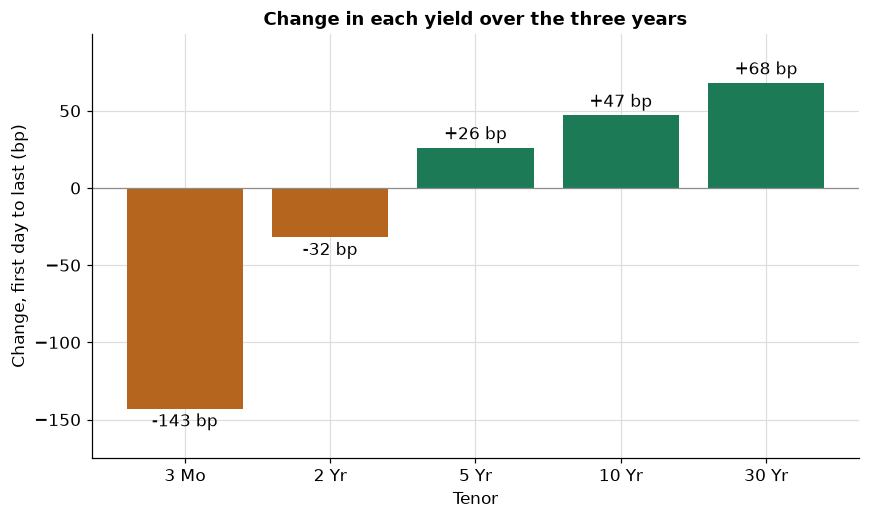

In [23]:
change = levels["change_bp"]

fig, ax = plt.subplots()
# one bar for each tenor: rises in green, falls in orange
bars = ax.bar(change.index, change.values, color=["#1c7a57" if value >= 0 else "#b5651d" for value in change])
ax.bar_label(bars, fmt="%+.0f bp", padding=3)
ax.axhline(0, color="#8c8c8c", linewidth=0.8)
ax.set_axisbelow(True)
ax.margins(y=0.15)
ax.set_xlabel("Tenor")
ax.set_ylabel("Change, first day to last (bp)")
ax.set_title("Change in each yield over the three years")
plt.show()

* The bars grow from negative on the left to positive on the right as the tenor lengthens: the 3 Mo down 143 bp, the 30 Yr up 68 bp. The zero line separates the tenors that ended lower from those that ended higher.

## 10.5 Daily Changes

**Predict 2**

On its largest single day in either direction, which moved more: the 2 Yr or the 10 Yr?

> A) The 2 Yr.
>
> B) The 10 Yr.
>
> C) They moved the same.

Decide, then run the cell.

In [24]:
# daily changes in bp for every series, computed on the whole file, then the three years selected
daily = pd.DataFrame({name: md.change_bp(market[name], 1, units[name] == "pct") for name in market.columns})
daily_3y = daily.loc["2023-10-03":"2026-10-02"]

# round to 6 decimals before ranking, as on day 6: binary noise must not break a tie between equal moves
moved = daily_3y[YIELDS].round(6)

# the largest rise and fall of each tenor, with the first date it happened, and the average size of a day's move
moves = pd.DataFrame({
    "largest_rise_bp": moved.max(),
    "rise_date": moved.idxmax().dt.date,
    "largest_fall_bp": moved.min(),
    "fall_date": moved.idxmin().dt.date,
    "mean_abs_bp": daily_3y[YIELDS].abs().mean(),
})
(moves.style
    .format({"largest_rise_bp": "{:+.1f}", "largest_fall_bp": "{:+.1f}", "mean_abs_bp": "{:.1f}"})
    .set_caption("Largest rise and fall of each tenor, in bp, and the average size of a day's move"))

,largest_rise_bp,rise_date,largest_fall_bp,fall_date,mean_abs_bp
3 Mo,+9.0,2025-11-03,-11.0,2024-09-18,1.4
2 Yr,+23.0,2024-04-10,-28.0,2024-08-02,4.3
5 Yr,+24.0,2024-04-10,-24.0,2023-11-14,4.5
10 Yr,+19.0,2024-04-10,-19.0,2023-11-14,4.2
30 Yr,+17.0,2025-04-07,-16.0,2023-12-14,4.0


* The answer is A. The 2 Yr's largest day was a fall of 28 bp on 2024-08-02; its largest rise was 23 bp, first on 2024-04-10 and again on 2024-10-04. The 10 Yr's largest fall was 19 bp, on two days: 2023-11-14, the date the table shows, and 2024-08-02, the same day as the 2 Yr's fall. Its largest rise was 19 bp on 2024-04-10.
* A typical day was much smaller: the average size of a daily move, ignoring the sign, was 4.3 bp for the 2 Yr and 4.2 bp for the 10 Yr.
* The data gives the size and the date of the 2024-08-02 fall, and nothing else. Why it happened is a question for a dated source, and this notebook reads none, so it gives no reason.
* The rounding to six decimals comes before `max`, `min`, `idxmax`, and `idxmin`, as on day 6. Unrounded, the 10 Yr's two 19 bp falls are stored as -18.99999999999995 and -19.00000000000004, so `idxmin` would name 2024-08-02 as the only largest fall. `.round(1)` on the last line changes only the display.

Q. Draw each tenor's largest rise and largest fall.

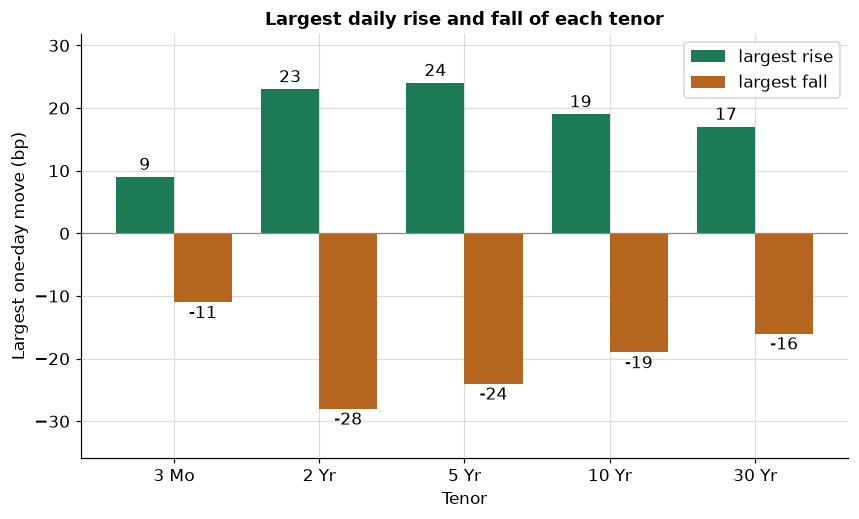

In [25]:
positions = list(range(len(moves)))

fig, ax = plt.subplots()
# the largest rise in green and the largest fall in orange, side by side for each tenor
rises = ax.bar([p - 0.2 for p in positions], moves["largest_rise_bp"], width=0.4, color="#1c7a57", label="largest rise")
falls = ax.bar([p + 0.2 for p in positions], moves["largest_fall_bp"], width=0.4, color="#b5651d", label="largest fall")
ax.bar_label(rises, fmt="%.0f", padding=2)
ax.bar_label(falls, fmt="%.0f", padding=2)
ax.axhline(0, color="#8c8c8c", linewidth=0.8)
ax.set_xticks(positions, moves.index)
ax.set_axisbelow(True)
ax.margins(y=0.15)
ax.set_xlabel("Tenor")
ax.set_ylabel("Largest one-day move (bp)")
ax.set_title("Largest daily rise and fall of each tenor")
ax.legend(loc="upper right")
plt.show()

* Each pair is one tenor's biggest day up and its biggest day down. The 2 Yr's pair is the tallest: its largest fall was 28 bp. The picture gives sizes only; the dates are in the table, and no reason is given for either.

## 10.6 Volatility Regimes

Day 7's volatility is the sample standard deviation of daily changes in bp over a trailing window. Over 63 rows it moves slowly enough to show stretches of calm and stretches of large moves: **regimes**, described here only by their size and dates.

**Predict 3**

On 2026-10-02, is the 10 Yr's 63-row volatility nearer its three-year low or its three-year high?

> A) Nearer its low.
>
> B) Nearer its high.
>
> C) At its high.

Decide, then run the cell.

In [26]:
VOL_SERIES = ["2 Yr", "10 Yr", "ig_spread_bp", "hy_spread_bp"]
# 63-row volatility of daily changes, bp per day: full windows on the whole file, then the three years
vol_63 = pd.DataFrame({name: md.rolling_vol_bp(daily[name].dropna(), 63) for name in VOL_SERIES}).loc["2023-10-03":"2026-10-02"]

regimes = pd.DataFrame({
    "low": vol_63.min(),
    "low_date": vol_63.idxmin().dt.date,
    "high": vol_63.max(),
    "high_date": vol_63.idxmax().dt.date,
    "last": vol_63.iloc[-1],
    # the share of the three years' values at or below the last one, in percent
    "last_share_at_or_below_pct": (vol_63 <= vol_63.iloc[-1]).mean() * 100,
})
(regimes.style
    .format({"low": "{:.2f}", "high": "{:.2f}", "last": "{:.2f}", "last_share_at_or_below_pct": "{:.0f}"})
    .set_caption("63-row volatility of daily changes (bp per day): low, high, last, and the share of values at or below the last"))

,low,low_date,high,high_date,last,last_share_at_or_below_pct
2 Yr,2.95,2026-02-04,8.43,2024-02-14,5.39,47
10 Yr,3.11,2026-02-03,8.25,2023-12-20,4.63,34
ig_spread_bp,0.81,2025-03-20,1.99,2025-06-17,1.09,63
hy_spread_bp,3.22,2025-12-24,8.27,2025-06-11,5.41,73


* The answer is A. The 10 Yr's 63-row volatility ended at 4.63 bp a day, against a low of 3.11 on 2026-02-03 and a high of 8.25 on 2023-12-20. 34 percent of the three years' values were at or below the last one.
* The 2 Yr's ranged from 2.95 (2026-02-04) to 8.43 (2024-02-14) bp a day.
* The synthetic spreads have their own regimes: the synthetic high yield spread's ranged from 3.22 to 8.27 bp a day, highest on 2025-06-11. The generator switches between a calm and a stressed state at random, so those dates mean nothing outside this file.
* These are per day. Annualised by day 7's convention, the 10 Yr's last value would be 73.5 bp a year.

Q. The average 63-row volatility by calendar year. (2023 holds only the last quarter, 2026 the first nine months.)

In [27]:
# group the dates by calendar year and average each year's values
# .groupby(year).mean() averages each calendar year's values; the styled version writes two decimals
(vol_63.groupby(vol_63.index.year).mean().style
    .format("{:.2f}")
    .set_caption("Average 63-row volatility by calendar year (bp per day)"))

,2 Yr,10 Yr,ig_spread_bp,hy_spread_bp
date,,,,
2023,6.37,7.42,1.26,4.26
2024,6.55,6.00,1.04,4.50
2025,5.38,5.08,1.22,5.22
2026,4.53,4.14,1.09,5.07


* The 10 Yr's yearly average went 7.42 (2023), 6.00 (2024), 5.08 (2025), 4.14 (2026) bp a day; the 2 Yr's 6.37 (2023), 6.55 (2024), 5.38 (2025), 4.53 (2026).
* A yearly average of a rolling measure smooths it twice. It describes the year as a whole and hides the highs and lows the table above shows.

Q. Draw the 63-row volatility of the 2 Yr and 10 Yr, with the 10 Yr's low, high, and last values marked.

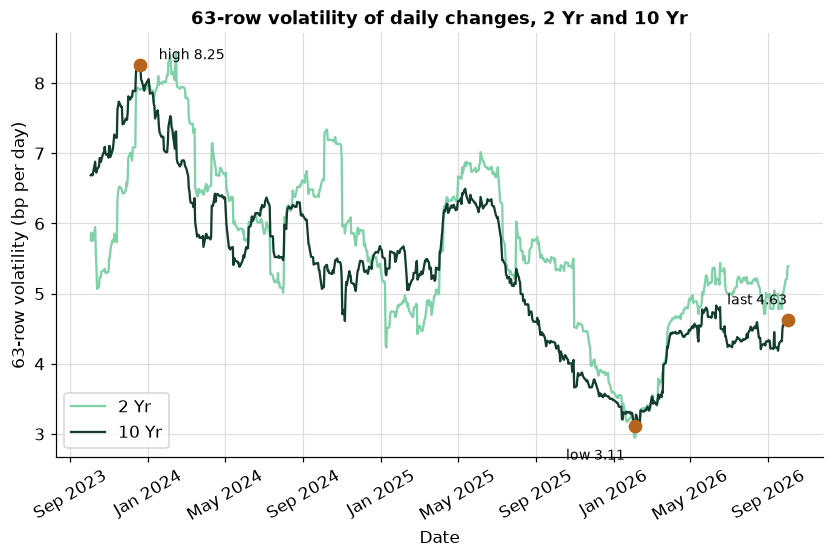

In [28]:
import matplotlib.dates as mdates

fig, ax = plt.subplots()
ax.plot(vol_63.index, vol_63["2 Yr"], color="#7fd1a8", label="2 Yr")
ax.plot(vol_63.index, vol_63["10 Yr"], color="#123d2f", label="10 Yr")
# mark the 10 Yr's lowest value, highest value, and last value
marks = [("low", pd.Timestamp(regimes.loc["10 Yr", "low_date"]), (-45, -22)), ("high", pd.Timestamp(regimes.loc["10 Yr", "high_date"]), (12, 4)),
         ("last", vol_63.index[-1], (-40, 10))]
for label, day, offset in marks:
    value = vol_63.loc[day, "10 Yr"]
    ax.plot(day, value, "o", color="#b5651d", markersize=8)
    ax.annotate(f"{label} {value:.2f}", (day, value), textcoords="offset points", xytext=offset, fontsize=9)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.tick_params(axis="x", rotation=30)
ax.set_xlabel("Date")
ax.set_ylabel("63-row volatility (bp per day)")
ax.set_title("63-row volatility of daily changes, 2 Yr and 10 Yr")
ax.legend(loc="lower left")
plt.show()

* The dark line is the 10 Yr and the light green line the 2 Yr. The three orange dots mark the 10 Yr's lowest, highest, and last values: the last sits near the bottom of the range, as the answer said.
* Regimes show up as long stretches where a line stays high or low. They are described by size and date only.

## 10.7 Where Each Series Sits: `summary_table` on 2026-10-02

**Predict 4**

The 10 Yr's percentile rank on 2026-10-02 is 99.6. Its window holds 252 values, today's included. How many of them are at or below today's 5.28?

> A) 99.
>
> B) 250.
>
> C) 251.

Decide, then run the cell.

In [29]:
# every series of the case study, every measure, as of the last market date
today = md.summary_table(market, "2026-10-02", units)

# the percentile rank is a count over 252, in percent: turn it back into the count
print(f"10 Yr: {today.loc['10 Yr', 'pct_rank'] * 252 / 100:.0f} of 252 window values at or below {today.loc['10 Yr', 'level']:.2f}")
# a styled table: background_gradient shades the rank column from 0 to 100 (Excel: Conditional Formatting, Color Scales)
(today.style
    .format({"level": "{:.2f}", "chg_1d_bp": "{:+.1f}", "chg_1w_bp": "{:+.1f}", "chg_1m_bp": "{:+.1f}", "zscore": "{:+.2f}", "pct_rank": "{:.1f}"})
    .background_gradient(subset=["pct_rank"], cmap="Greens", vmin=0, vmax=100)
    .set_caption("summary_table on 2026-10-02 for all twelve series (the two spreads are synthetic)"))

10 Yr: 251 of 252 window values at or below 5.28


,unit,level,chg_1d_bp,chg_1w_bp,chg_1m_bp,zscore,pct_rank
series,,,,,,,
3 Mo,pct,4.19,+2.0,-5.0,+27.0,+2.58,98.0
2 Yr,pct,4.83,+5.0,+2.0,+44.0,+2.51,98.0
5 Yr,pct,5.06,+5.0,+8.0,+52.0,+2.80,99.6
10 Yr,pct,5.28,+4.0,+11.0,+49.0,+3.08,99.6
30 Yr,pct,5.63,+2.0,+14.0,+36.0,+3.08,99.6
2s10s,bp,45.00,-1.0,+9.0,+5.0,-0.51,28.2
5s30s,bp,57.00,-3.0,+6.0,-16.0,-2.07,6.0
3m10y,bp,109.00,+2.0,+16.0,+22.0,+2.07,100.0
2s5s10s,bp,1.00,+1.0,+3.0,+11.0,+2.70,98.8


* The answer is C: 251 of 252, so 251 / 252 x 100 = 99.6. One value in the window, 5.29 on 2026-09-30, was higher.
* All five yields had z-scores between 2.51 and 3.08 and percentile ranks of 98.0 or more: each was near the top of its own one-year history on 2026-10-02.
* The curve measures sat in different places. 2s10s, at 45 bp, had a percentile rank of 28.2; 5s30s, at 57 bp, 6.0, the lowest of the 12; 3m10y, at 109 bp, 100.0, the highest value in its window.
* The synthetic investment grade spread, 97.0 bp, had a percentile rank of 61.1; the synthetic high yield spread, 328.7 bp, 73.8.
* A z-score near 3 or a rank near 100 says where today sits in its own past year. It does not say the next move is down, or up: this course never reads it that way.

Q. Draw every series' z-score and percentile rank on the last date, side by side.

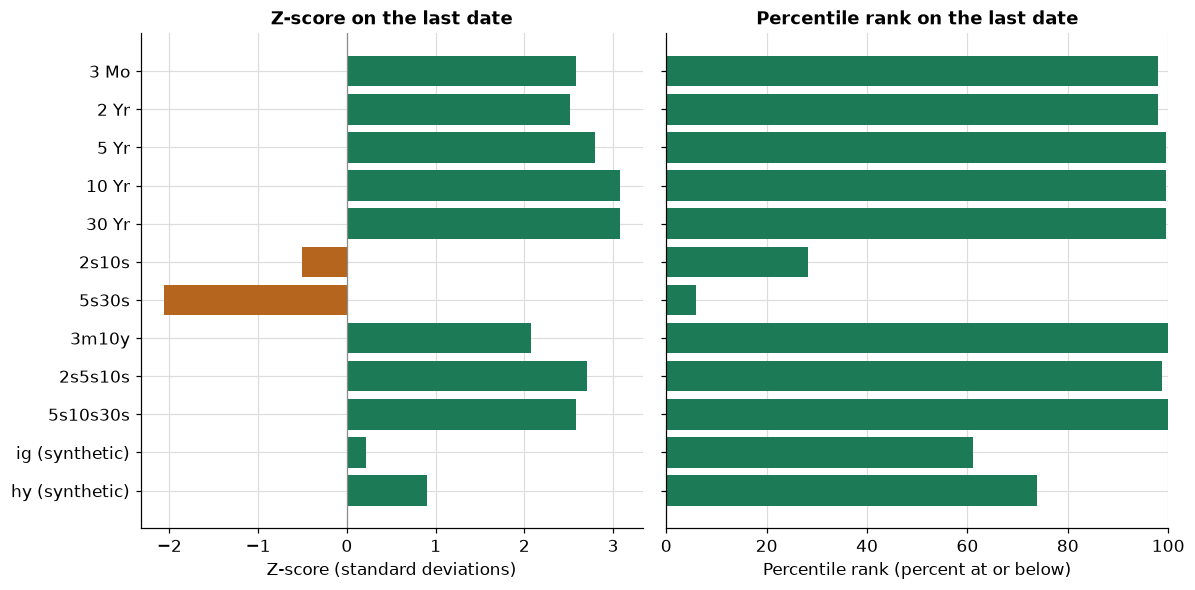

In [30]:
# the first series at the top: reverse the order for a horizontal bar chart
order = list(today.index)[::-1]
labels = [name.replace("_spread_bp", " (synthetic)") for name in order]

fig, axes = plt.subplots(1, 2, figsize=(11, 5.5), sharey=True)
axes[0].barh(labels, today.loc[order, "zscore"], color=["#1c7a57" if z >= 0 else "#b5651d" for z in today.loc[order, "zscore"]])
axes[0].axvline(0, color="#8c8c8c", linewidth=0.8)
axes[0].set_xlabel("Z-score (standard deviations)")
axes[0].set_title("Z-score on the last date")
axes[1].barh(labels, today.loc[order, "pct_rank"], color="#1c7a57")
axes[1].set_xlim(0, 100)
axes[1].set_xlabel("Percentile rank (percent at or below)")
axes[1].set_title("Percentile rank on the last date")
for ax in axes:
    ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

* Left: each series' z-score, from the mean at zero. Right: the same twelve series as percentile ranks on one scale from 0 to 100. The five yields sit near the top of their one-year ranges; 5s30s has the lowest rank, 6.0.
* Both panels describe where each series sits in its own past year, and nothing about what comes next.

## 10.8 The Shape of the Curve

A slope is negative when the shorter yield is higher; a butterfly is negative when the belly yields less than the average of its wings.

**Predict 5**

On how many of the 750 days was 2s10s negative: the 2 Yr above the 10 Yr?

> A) About a tenth.
>
> B) About a third.
>
> C) About two thirds.

Decide, then run the cell.

In [31]:
SHAPES = ["2s10s", "5s30s", "3m10y", "2s5s10s", "5s10s30s"]
# rounded to 9 decimals first: binary noise such as 1e-14 left by (x - y) * 100 must not count as a sign
shape = three_years[SHAPES].round(9)

signs = pd.DataFrame({
    "negative_days": (shape < 0).sum(),
    "zero_days": (shape == 0).sum(),
    "positive_days": (shape > 0).sum(),
    "first": shape.iloc[0],
    "last": shape.iloc[-1],
    "low": shape.min(),
    "high": shape.max(),
})
print(f"the last day 2s10s was negative: {shape.index[shape['2s10s'] < 0][-1].date()}")
print(f"the last day 3m10y was negative: {shape.index[shape['3m10y'] < 0][-1].date()}")
(signs.style
    .format({"first": "{:.1f}", "last": "{:.1f}", "low": "{:.1f}", "high": "{:.1f}"})
    .set_caption("Days of each sign for slopes and butterflies, and their first, last, low, and high (bp)"))

the last day 2s10s was negative: 2024-09-05
the last day 3m10y was negative: 2025-10-16


,negative_days,zero_days,positive_days,first,last,low,high
2s10s,227,3,520,-34.0,45.0,-53.0,74.0
5s30s,0,0,750,15.0,57.0,3.0,124.0
3m10y,385,8,357,-81.0,109.0,-165.0,109.0
2s5s10s,742,1,7,-36.0,1.0,-53.0,3.0
5s10s30s,748,2,0,-13.0,-13.0,-27.0,0.0


* The answer is B: 227 of 750 days, 30 percent. 2s10s started at -34 bp, was last negative on 2024-09-05, and ended at 45 bp. It was exactly zero on 3 days.
* 3m10y was negative on 385 days, last on 2025-10-16; it ranged from -165 to 109 bp and ended at its high.
* 5s30s was positive on every day of the window, from 3 to 124 bp.
* 2s5s10s was negative on 742 days and ended at 1 bp, its belly about level with its wings. 5s10s30s was never positive: its high was 0 bp. Day 9's sign convention throughout: 2 x belly less both wings.
* Without the rounding, 2s10s computed as `(10 Yr - 2 Yr) * 100` can come out as a tiny positive or negative number on a day the two yields were equal, and the zero days would be miscounted.

Q. Draw the days of each sign for the five shapes.

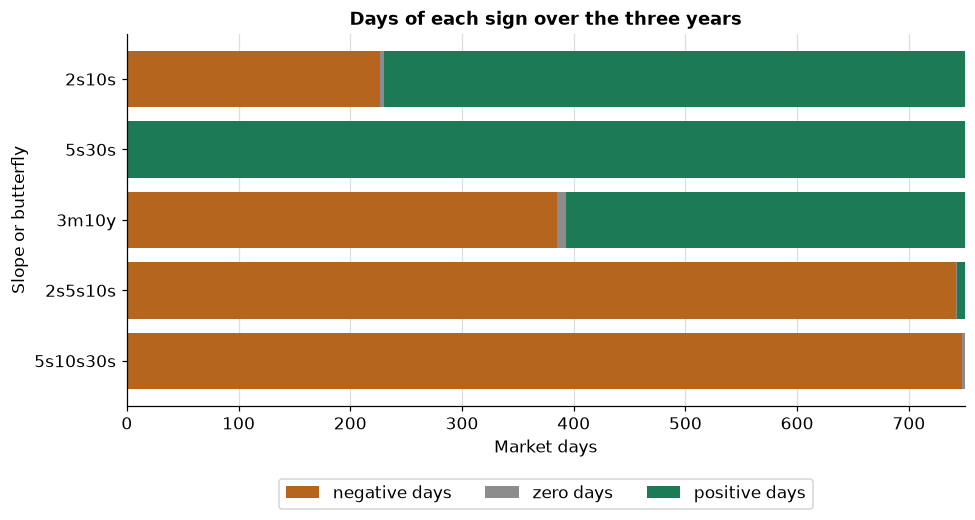

In [32]:
fig, ax = plt.subplots()
# one horizontal bar for each shape: negative days in orange, zero days in grey, positive days in green, side by side
names = list(signs.index)[::-1]
negative = signs.loc[names, "negative_days"]
zero = signs.loc[names, "zero_days"]
positive = signs.loc[names, "positive_days"]
ax.barh(names, negative, color="#b5651d", label="negative days")
ax.barh(names, zero, left=negative, color="#8c8c8c", label="zero days")
ax.barh(names, positive, left=negative + zero, color="#1c7a57", label="positive days")
ax.set_axisbelow(True)
ax.set_xlabel("Market days")
ax.set_ylabel("Slope or butterfly")
ax.set_title("Days of each sign over the three years")
ax.legend(loc="lower center", ncols=3, bbox_to_anchor=(0.5, -0.3))
plt.tight_layout()
plt.show()

* Each bar is the 750 days split by sign. 2s10s has an orange part, 227 days. 5s30s has none: always positive. 5s10s30s has no green: never positive.
* Slopes and flies are separate facts about the curve, and this picture shows five of them side by side.

## 10.9 The Synthetic Spreads

**Reminder: these two series are synthetic (invented by the course's generator, not ICE, Moody's, or any index).** They were simulated so that the course has a credit spread history it may publish. They describe no real market, and no date in them was chosen to resemble one.

**Predict 6**

The generator builds each day's high yield shock from a multiple of the investment grade shock plus noise of its own. Is the correlation of the two series' daily changes over the three years closer to 0, to 0.5, or to 1?

> A) Closer to 0.
>
> B) Closer to 0.5.
>
> C) Closer to 1.

Decide, then run the cell.

In [33]:
# the two SYNTHETIC spreads over the three years
synthetic = three_years[["ig_spread_bp", "hy_spread_bp"]]
spread_stats = pd.DataFrame({
    "first": synthetic.iloc[0], "last": synthetic.iloc[-1],
    "low": synthetic.min(), "low_date": synthetic.idxmin().dt.date,
    "high": synthetic.max(), "high_date": synthetic.idxmax().dt.date,
})
print(spread_stats.to_string())

# the gap between them, and how their daily changes move together
gap = synthetic["hy_spread_bp"] - synthetic["ig_spread_bp"]
print(f"high yield less investment grade: {gap.min():.1f} to {gap.max():.1f} bp, {gap.iloc[-1]:.1f} bp on {gap.index[-1].date()}")
print(f"high yield above investment grade on every day: {bool((gap > 0).all())}")
print(f"correlation of daily changes: {daily_3y['ig_spread_bp'].corr(daily_3y['hy_spread_bp']):.2f}")
print("Both spreads are SYNTHETIC: invented by the course, not any real index")

              first   last    low    low_date   high   high_date
ig_spread_bp   93.5   97.0   80.7  2025-06-12  114.2  2025-03-26
hy_spread_bp  234.3  328.7  198.7  2025-06-12  394.3  2025-04-21
high yield less investment grade: 118.0 to 281.4 bp, 231.7 bp on 2026-10-02
high yield above investment grade on every day: True
correlation of daily changes: 0.84
Both spreads are SYNTHETIC: invented by the course, not any real index


* The answer is C: 0.84. On most days the two synthetic spreads moved in the same direction, because the generator builds one from the other.
* The synthetic investment grade spread ran from 80.7 bp (2025-06-12) to 114.2 bp (2025-03-26) and ended at 97.0. The synthetic high yield spread ran from 198.7 (2025-06-12) to 394.3 (2025-04-21) and ended at 328.7.
* The gap between them ran from 118.0 to 281.4 bp. On 2026-10-02 it was 231.7 bp.
* Both end-of-window levels sit close to the book's market-value weighted spreads: the generator pinned each series to the September book's weighted `oas` on 2026-09-30. That is how the synthetic market and the synthetic book agree.
* Correlation here is the Pearson coefficient, pandas' `corr` default. It describes how the changes moved together in this file, nothing more.

Q. Draw the two synthetic spreads, and each day's change in one against the other.

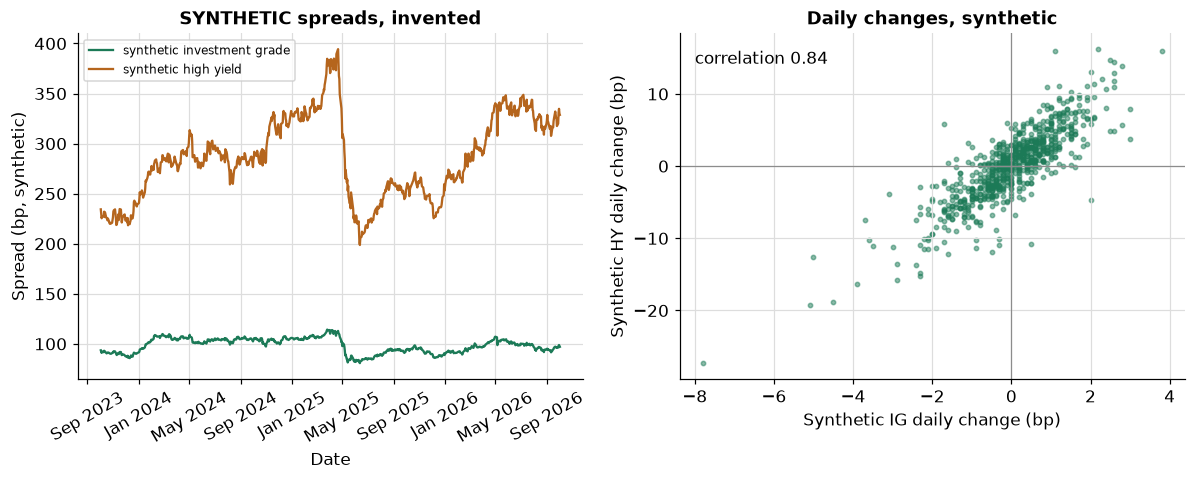

In [34]:
import matplotlib.dates as mdates

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
# left: the levels of the two SYNTHETIC spreads
axes[0].plot(synthetic.index, synthetic["ig_spread_bp"], color="#1c7a57", label="synthetic investment grade")
axes[0].plot(synthetic.index, synthetic["hy_spread_bp"], color="#b5651d", label="synthetic high yield")
axes[0].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
axes[0].tick_params(axis="x", rotation=30)
axes[0].set_xlabel("Date")
axes[0].set_ylabel("Spread (bp, synthetic)")
axes[0].set_title("SYNTHETIC spreads, invented")
axes[0].legend(loc="upper left", fontsize=8)
# right: one dot for each day, the change in each spread
axes[1].scatter(daily_3y["ig_spread_bp"], daily_3y["hy_spread_bp"], s=8, color="#1c7a57", alpha=0.5)
axes[1].axhline(0, color="#8c8c8c", linewidth=0.8)
axes[1].axvline(0, color="#8c8c8c", linewidth=0.8)
axes[1].text(0.03, 0.95, f"correlation {daily_3y['ig_spread_bp'].corr(daily_3y['hy_spread_bp']):.2f}", transform=axes[1].transAxes, va="top")
axes[1].set_xlabel("Synthetic IG daily change (bp)")
axes[1].set_ylabel("Synthetic HY daily change (bp)")
axes[1].set_title("Daily changes, synthetic")
plt.tight_layout()
plt.show()

* Left: two invented series that rise and fall together, high yield above investment grade throughout. Right: each dot is one day. The dots lie along a rising line, so the two changes had the same sign on most days: a correlation of 0.84, as the generator built them.
* Both panels are synthetic (invented by the course's generator, not ICE, Moody's, or any index).

## 10.10 Four Panels

Q. One figure, four panels, one shared date axis: the yields, the slopes, the 63-row volatility, and the synthetic spreads.

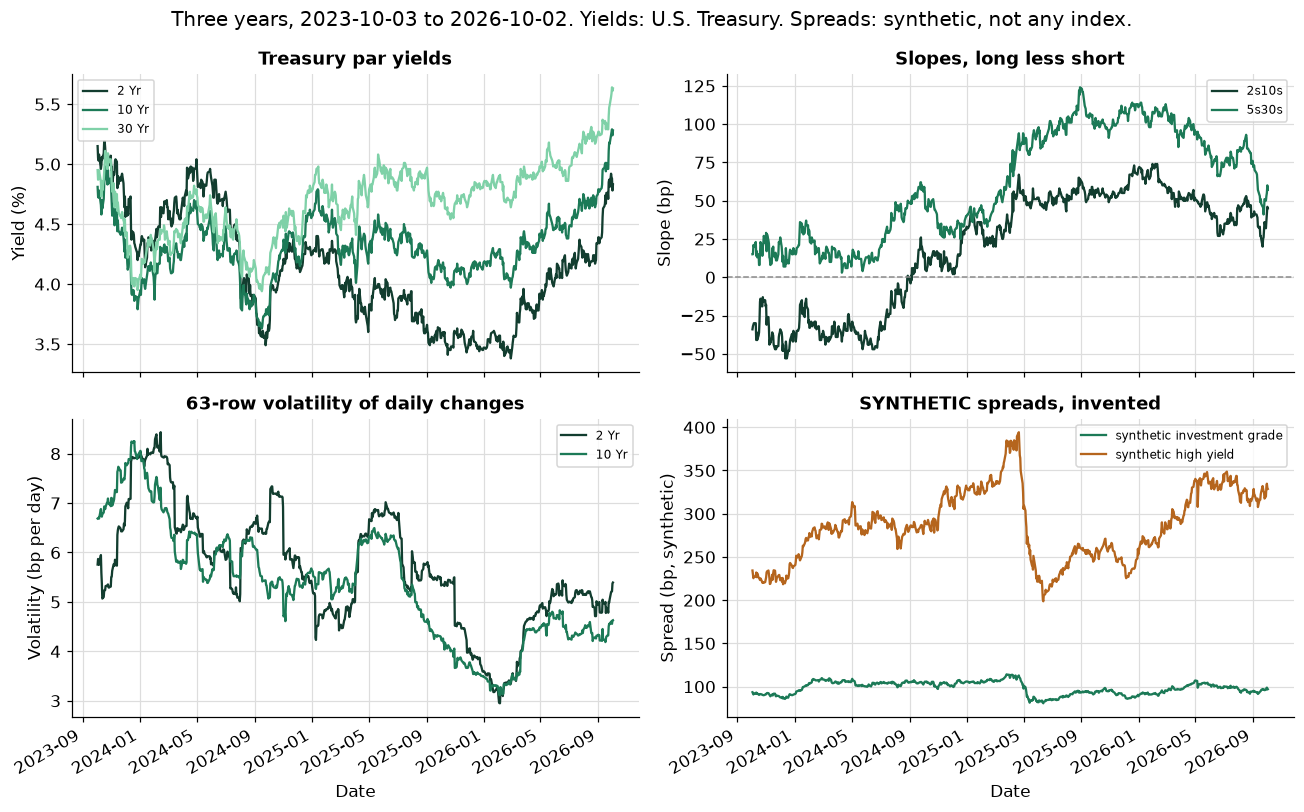

In [35]:
# a 2 x 2 grid of panels that share the date axis
fig, axes = plt.subplots(2, 2, figsize=(12, 7.5), sharex=True)

# top left: three tenors, in percent
for tenor in ["2 Yr", "10 Yr", "30 Yr"]:
    axes[0, 0].plot(three_years.index, three_years[tenor], label=tenor)
axes[0, 0].set_title("Treasury par yields")
axes[0, 0].set_ylabel("Yield (%)")

# top right: two slopes, in bp, with zero marked
for name in ["2s10s", "5s30s"]:
    axes[0, 1].plot(three_years.index, three_years[name], label=name)
axes[0, 1].axhline(0, color="#8c8c8c", linestyle="--", linewidth=1)
axes[0, 1].set_title("Slopes, long less short")
axes[0, 1].set_ylabel("Slope (bp)")

# bottom left: 63-row volatility of daily changes, bp per day
for tenor in ["2 Yr", "10 Yr"]:
    axes[1, 0].plot(vol_63.index, vol_63[tenor], label=tenor)
axes[1, 0].set_title("63-row volatility of daily changes")
axes[1, 0].set_ylabel("Volatility (bp per day)")

# bottom right: the SYNTHETIC spreads, labelled as such
axes[1, 1].plot(three_years.index, three_years["ig_spread_bp"], color="#1c7a57", label="synthetic investment grade")
axes[1, 1].plot(three_years.index, three_years["hy_spread_bp"], color="#b5651d", label="synthetic high yield")
axes[1, 1].set_title("SYNTHETIC spreads, invented")
axes[1, 1].set_ylabel("Spread (bp, synthetic)")

for ax in axes.flat:
    ax.legend(fontsize=8)
    ax.set_xlabel("Date")
# slant the dates on the bottom panels so they do not run into each other
fig.autofmt_xdate()
fig.suptitle("Three years, 2023-10-03 to 2026-10-02. Yields: U.S. Treasury. Spreads: synthetic, not any index.")
fig.tight_layout()
plt.show()

* Top left: the short end above the long end at the start, the long end above at the end. Top right: 2s10s below the zero line for its first stretch, then above it; 5s30s above it throughout. Bottom left: the volatility regimes of section 10.6. Bottom right: two invented series that move together.
* Every number in the four panels is in a table above. A chart shows the shape; the tables hold the numbers to quote.

**Observations**

* **Levels.** Over 750 market days from 2023-10-03 to 2026-10-02, the 3 Mo fell 143 bp, from 5.62 to 4.19 percent, and the 30 Yr rose 68 bp, from 4.95 to 5.63. The 10 Yr rose 47 bp and reached its three-year high, 5.29, on 2026-09-30.
* **Changes.** The largest daily move of the five tenors was the 2 Yr's 28 bp fall on 2024-08-02; the 10 Yr fell 19 bp that day, matching its largest fall, first seen on 2023-11-14. A typical day moved the 10 Yr 4.2 bp.
* **Volatility.** The 10 Yr's 63-row volatility ranged from 3.11 to 8.25 bp a day and ended at 4.63, nearer its low.
* **Where each series sits.** On 2026-10-02 every yield had a percentile rank of 98.0 or more in its one-year window, and the 10 Yr's z-score was 3.08. 5s30s had the lowest percentile rank of the 12 series, 6.0.
* **Shape.** 2s10s was negative on 227 of the 750 days, last on 2024-09-05, and ended at 45 bp. 3m10y went from -81 to 109 bp. 5s30s stayed positive throughout.
* **Synthetic spreads.** The invented investment grade and high yield spreads ended at 97.0 and 328.7 bp, with daily changes correlated at 0.84, as the generator built them.

These describe three years of one public file and one invented one. None of them says why a series moved, what it does next, or what anyone should do.

## 10.11 Live: The Same Table from FRED

*This product uses the FRED&reg; API but is not endorsed or certified by the Federal Reserve Bank of St. Louis.*

Two live cells. The first pulls `DGS2` and `DGS10` and checks that `summary_table` built from FRED's series equals the one built from the snapshot. The second pulls ICE BofA's investment grade and high yield OAS, `BAMLC0A0CM` and `BAMLH0A0HYM2`, the real series the synthetic spreads stand in for, and prints only their metadata: ICE's terms on FRED say the data may not be published or distributed without ICE's written approval. Their values appear only on your own screen, and only if you set `SHOW_LICENSED_VALUES = True` on your own machine.

Q. Run the key cell.

In [36]:
try:
    fred_key = md.get_secret("FRED_API_KEY", env_file=ENV_FILE)
    print("FRED key: found. It is held in memory and is never printed.")
except RuntimeError as error:
    fred_key = None
    print(f"FRED key: not found. Live cells will be skipped. {error}")

FRED key: not found. Live cells will be skipped. Secret FRED_API_KEY not found. Looked in: the environment variable FRED_API_KEY, Colab's Secrets panel, and the file .env given as env_file.


Q. Pull the 2 Yr and 10 Yr from FRED, build the summary of the 10 Yr and 2s10s as of 2026-10-01, and compare it with the snapshot's.

In [37]:
# a live cell: it needs your key and the network
if fred_key is None:
    print(NO_KEY_MESSAGE)
else:
    live_pulled = {}
    for live_id, live_tenor in [("DGS2", "2 Yr"), ("DGS10", "10 Yr")]:
        live_pulled[live_tenor] = md.fred_series(live_id, fred_key, start="2023-10-03")
        print(f"{live_id}: {len(live_pulled[live_tenor])} rows, {live_pulled[live_tenor].index[0].date()} to {live_pulled[live_tenor].index[-1].date()}")

    # FRED's "." days dropped, then the same two series as the snapshot table
    live_curve = pd.DataFrame(live_pulled).dropna()
    live_data = pd.DataFrame({"10 Yr": live_curve["10 Yr"], "2s10s": md.slope_bp(live_curve, "2 Yr", "10 Yr")})
    # 2026-10-01: a date FRED and the snapshot both hold; rows after it are ignored by summary_table
    live_table = md.summary_table(live_data, "2026-10-01", units)
    live_snapshot = md.summary_table(market[["10 Yr", "2s10s"]], "2026-10-01", units)
    pd.testing.assert_frame_equal(live_table, live_snapshot, check_exact=False, rtol=0, atol=1e-9)
    print("summary_table from FRED equals the snapshot's on 2026-10-01, to 1e-9")

Live cell skipped: no FRED key was found. Every other cell runs without one.


* The saved output is the skip message, because the saved run had no key.
* **With your key** you see each series' row count and its first and last date (the last a day or two before the day you run it), then the check line. FRED's `DGS` series are Treasury's own numbers, so the 252-row windows hold the same values and the tables agree. FRED may hold rows after the snapshot ends; `summary_table` ignores every row after its as-of date, which is the rule of section 10.2 at work on live data.

Q. Pull ICE's investment grade and high yield OAS for the same three years. Print only what describes the pull, never a value.

In [38]:
# a live cell: ICE BofA data, metadata only unless you choose otherwise on your own machine
if fred_key is None:
    print(NO_KEY_MESSAGE)
else:
    live_ice = {}
    for live_id in ["BAMLC0A0CM", "BAMLH0A0HYM2"]:
        # held in memory only: never cached, never written to a file
        live_ice[live_id] = md.fred_series(live_id, fred_key, start="2023-10-03")
        live_dots = int(live_ice[live_id].isna().sum())
        live_weekend = int((live_ice[live_id].index.dayofweek >= 5).sum())
        print(f"{live_id}: {len(live_ice[live_id])} rows, {live_ice[live_id].index[0].date()} to {live_ice[live_id].index[-1].date()}, "
              f"{live_dots} '.' rows, {live_weekend} weekend rows")
        assert live_ice[live_id].index.is_unique and live_ice[live_id].index.is_monotonic_increasing

    if SHOW_LICENSED_VALUES:
        # your own screen only: percent to bp, then today's table for both series
        live_ice_bp = pd.DataFrame(live_ice) * 100
        live_ice_table = md.summary_table(live_ice_bp, live_ice_bp.index[-1], {live_id: "bp" for live_id in live_ice_bp.columns})
        print(live_ice_table.round(2).to_string())
    else:
        print("Values not shown: SHOW_LICENSED_VALUES is False")

Live cell skipped: no FRED key was found. Every other cell runs without one.


* **With your key** you see, for each series, about three years of daily rows ending a day or two before the day you run it, the number of `.` rows, and a few weekend rows: FRED's notes say month ends that fall on a weekend carry a row from a month-end adjustment. Then the line saying values are not shown.
* With `SHOW_LICENSED_VALUES = True`, on your own machine, the second branch converts percent to bp and prints the same seven measures for ICE's two series as `summary_table` gave the synthetic ones. `summary_table` drops each column's `.` rows itself. Keep that output on your screen: do not save, share, or record it.

## Excel Side by Side

The whole summary row can be built in a sheet, one formula per column. Every formula below was typed into Excel (16.0 build 20430, 2026-10-04) on a sheet holding the Treasury file's 2,940 dates in A2:A2941, the 2 Yr in B, the 10 Yr in C, and 2s10s in D as `=(C2-B2)*100` filled down. The as-of date goes in H1; row 3 is the 10 Yr, row 4 is 2s10s.

| Column | Excel, row 3 (the 10 Yr) | Python |
| --- | --- | --- |
| position | `=XMATCH($H$1,$A$2:$A$2941,-1)` | (`summary_table` slices with `.loc[:as_of]`) |
| level | `=XLOOKUP($H$1,$A$2:$A$2941,C$2:C$2941,,-1)` | `value_as_of` |
| chg_1d_bp | `=(I3-INDEX(C$2:C$2941,H3-1))*100` | `change_bp(series, 1).iloc[-1]` |
| chg_1w_bp | `=(I3-XLOOKUP($H$1-7,$A$2:$A$2941,C$2:C$2941,,-1))*100` | `change_since_bp(..., as_of - 7 days)` |
| chg_1m_bp | `=(I3-XLOOKUP(EDATE($H$1,-1),$A$2:$A$2941,C$2:C$2941,,-1))*100` | `change_since_bp(..., as_of - 1 month)` |
| zscore | `=STANDARDIZE(I3,AVERAGE(OFFSET(C$1,H3-251,0,252,1)),STDEV.S(OFFSET(C$1,H3-251,0,252,1)))` | `rolling_zscore(series, 252).iloc[-1]` |
| pct_rank | `=COUNTIF(OFFSET(C$1,H3-251,0,252,1),"<="&I3)/COUNT(OFFSET(C$1,H3-251,0,252,1))*100` | `rolling_percentile_rank(series, 252).iloc[-1]` |

Row 4 is the same with column D, and without `*100` on the three changes, because 2s10s is already in bp: `=(I4-INDEX(D$2:D$2941,H4-1))`.

**The position.** `XMATCH` with match mode -1 finds the as-of date, or the last date before it, and returns its place in the list: on 2026-10-02 that is 2940, the last of the 2,940 rows. Everything else is read relative to it.

**The changes.** `XLOOKUP` with match mode -1 is day 4's as-of lookup. `INDEX(..., H3-1)` is the row before the as-of row, so the one-day change is from the previous observation whatever the calendar gap. `$H$1-7` and `EDATE($H$1,-1)` are the one-week and one-month dates, each looked up as-of.

**The window.** `OFFSET(C$1,H3-251,0,252,1)` is a range of 252 rows that ends on the as-of row: the test sheet confirmed `ROWS` of it is 252 and its last cell is the level. `STANDARDIZE` over it is day 8's z-score; `COUNTIF(...,"<="&I3)/COUNT(...)*100` is day 8's percentile rank. Change the date in H1 and the whole row recalculates.

| As of | 10 Yr level | 1 day | 1 week | 1 month | z-score | pct rank |
| --- | --- | --- | --- | --- | --- | --- |
| 2026-10-02 | 5.28 | 4.0 | 11.0 | 49.0 | 3.0752 | 99.6032 |
| 2026-09-30 | 5.29 | 3.0 | 18.0 | 56.0 | 3.2524 | 100.0000 |
| 2026-09-07 (holiday) | 4.78 | 1.0 | 3.0 | 13.0 | 2.1217 | 99.2063 |

2026-09-07, Labor Day, has no row: `XMATCH` and `XLOOKUP` with -1 fall back to Friday 2026-09-04, as `value_as_of` does.

Q. Do Python's tables equal Excel's sheet on all three dates?

In [39]:
# what the Excel sheet returned on each date, for each series and measure
excel_sheet = {'2026-10-02': {'10 Yr': {'level': 5.28, 'chg_1d_bp': 4.0000000000000036, 'chg_1w_bp': 11.000000000000032, 'chg_1m_bp': 49.00000000000002, 'zscore': 3.075234405274332, 'pct_rank': 99.60317460317461}, '2s10s': {'level': 45.000000000000014, 'chg_1d_bp': -0.9999999999999858, 'chg_1w_bp': 8.999999999999986, 'chg_1m_bp': 4.999999999999979, 'zscore': -0.5109000465103897, 'pct_rank': 28.174603174603174}}, '2026-09-30': {'10 Yr': {'level': 5.29, 'chg_1d_bp': 3.000000000000025, 'chg_1w_bp': 17.99999999999997, 'chg_1m_bp': 55.99999999999996, 'zscore': 3.2523556662886772, 'pct_rank': 100.0}, '2s10s': {'level': 41.000000000000014, 'chg_1d_bp': 4.0, 'chg_1w_bp': 14.999999999999947, 'chg_1m_bp': 1.9999999999999574, 'zscore': -0.8625493118841496, 'pct_rank': 23.015873015873016}}, '2026-09-07': {'10 Yr': {'level': 4.78, 'chg_1d_bp': 1.0000000000000675, 'chg_1w_bp': 3.000000000000025, 'chg_1m_bp': 12.99999999999999, 'zscore': 2.1217221866872187, 'pct_rank': 99.20634920634922}, '2s10s': {'level': 41.000000000000014, 'chg_1d_bp': -1.9999999999999574, 'chg_1w_bp': 0.0, 'chg_1m_bp': -4.999999999999986, 'zscore': -1.115249441356211, 'pct_rank': 16.26984126984127}}}

largest = 0.0
for as_of, by_series in excel_sheet.items():
    table = md.summary_table(pair, as_of, units)
    for name, values in by_series.items():
        for measure, excel_value in values.items():
            largest = max(largest, abs(table.loc[name, measure] - excel_value))
print(f"3 dates x 2 series x 6 measures against Excel: largest gap {largest:.1e}")

3 dates x 2 series x 6 measures against Excel: largest gap 5.5e-13


* 36 values, largest gap 5.5e-13. The sheet and the function are the same definitions written twice.

## Save the Day with Git

First, commit today's work. Then today's Git step closes the week: **a `week2` tag**, and a comparison of the two tags.

Q. What changed since the start of the day?

In [40]:
# the files Git tracks that changed, and how many lines
!git -C "{work}" status --short
!git -C "{work}" diff --stat

 M marketdata.py
 M test_marketdata.py
?? __pycache__/
?? bondmath.py
?? course3_excel_reference.csv
?? course3_fred_format_dgs10.json
?? course3_synthetic_spreads.csv
?? treasury_par_yields.csv


 marketdata.py      | 40 ++++++++++++++++++++++++++++++++++++++++
 test_marketdata.py | 35 +++++++++++++++++++++++++++++++++++
 2 files changed, 75 insertions(+)


* Two files modified (` M`): today's function and today's two tests. The data files, `bondmath.py`, and Python's `__pycache__` folder were never added, so they stay untracked (`??`).

Q. Commit them.

In [41]:
!git -C "{work}" add marketdata.py test_marketdata.py
!git -C "{work}" commit -q -m "Add summary_table, every measure as of one date, with its no-lookahead test" -m "Week 2 ends with one table that reads only rows on or before its as-of date."
!git -C "{work}" log --oneline -1

c2a2f63 Add summary_table, every measure as of one date, with its no-lookahead test


Q. Name the end of week 2, and list the names.

In [42]:
# tag names the last commit; tag alone lists the tags; --decorate shows the names
!git -C "{work}" tag week2
!git -C "{work}" tag
!git -C "{work}" log --oneline --decorate

week1
week2


c2a2f63 (HEAD -> main, tag: week2) Add summary_table, every measure as of one date, with its no-lookahead test
aab7ada Start of day 10: marketdata.py and test_marketdata.py as day 9 left them
b223f18 (tag: week1) Week 1 as it ended: the files at the week1 tag


* Two tags now. `week1` stays on the commit where week 1 ended, and `week2` is on today's commit, with `HEAD -> main`.

Q. What did week 2 add to the module and the tests? Compare the two tags.

In [43]:
# diff between two names: every change from the week1 commit to the week2 commit
!git -C "{work}" diff --stat week1 week2

 marketdata.py      | 216 ++++++++++++++++++++++++++++++++++++++++++++++++++
 test_marketdata.py | 229 +++++++++++++++++++++++++++++++++++++++++++++++++++++
 2 files changed, 445 insertions(+)


* 216 lines added to `marketdata.py` and 229 to `test_marketdata.py`, and nothing removed: week 2 only added code. They are the 10 functions and 22 tests that days 6 to 10 added, with their helpers, docstrings, and blank lines.
* A tag works anywhere a commit does: `git diff week1 week2 -- marketdata.py` shows the lines themselves, and `git log --oneline week1..week2` the commits between them.

## Bring It Home

Add today's function and tests to your own `my_bondmath` folder, and close the week there too. Open a PowerShell terminal in VS Code, with the course's `.venv` active.

**Step 1.** Go to your folder and open the two files.

```powershell
Set-Location "$HOME\projects\my_bondmath"
code marketdata.py
code test_marketdata.py
```

**Step 2.** Paste today's code at the end of each file. In `marketdata.py`, leave two blank lines after the last function and paste the code of the `%%writefile -a marketdata.py` cell in section 10.1, without its first line. In `test_marketdata.py`, do the same with the `%%writefile -a test_marketdata.py` cell in section 10.2. Save both. Your folder needs no week 1 rebuild: it has had its `week1` tag since day 5.

**Step 3.** Run the tests.

```powershell
python -m pytest -q test_marketdata.py
```

The last line says `42 passed`, or more if you kept your exercise tests.

**Step 4.** Read the change, commit, tag the week, and compare.

```powershell
git diff --stat
git add marketdata.py test_marketdata.py
git commit -m "Add summary_table, every measure as of one date, with its no-lookahead test" -m "Week 2 ends with one table that reads only rows on or before its as-of date."
git tag week2
git log --oneline --decorate -3
git diff --stat week1 week2
```

Your counts are larger than the notebook's if you kept your exercise functions or added other files during the week.

**In Colab**, download `marketdata.py` and `test_marketdata.py` from the work folder under `/tmp` in the file browser.

## You Can Now

* Build a summary row for any set of series with `summary_table`: level, three changes in bp, z-score, and percentile rank, all as of one date.
* Prove that a table reads only rows on or before its date, with an invented later row and an exact comparison.
* Describe three years of a curve and two spreads with numbers and dates, and keep every sentence to what the data was.
* Count a sign without being fooled by binary noise.
* Build the same summary row in Excel with `XMATCH`, `XLOOKUP`, `INDEX`, `EDATE`, `OFFSET`, `STANDARDIZE`, and `COUNTIF`.
* Close a week with `git tag` and compare two tags with `git diff --stat`.

Week 3 starts tomorrow with SQL: the course's holdings, trades, and market data in a SQLite database file, every query beside its pandas equivalent and proved equal with a new function, `assert_same_rows`.

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`. Give each exercise a real try first, then check your work against it.

The exercises use the second set: the 5 Yr and 30 Yr, `5s30s`, `5s10s30s`, and the synthetic high yield spread. Replace each `...` with your own code, then run the check cell.

Q. Run the next cell first. It reads the data, builds `second_set` and `second_units`, and defines `check`, a small function that marks your answers.

In [44]:
# the exercises' data: the Treasury file, the synthetic spreads, and a second set of series
read = dict(parse_dates=["date"], index_col="date", float_precision="round_trip")
curve = pd.read_csv("treasury_par_yields.csv", **read)
spreads = pd.read_csv("course3_synthetic_spreads.csv", **read)

# the second set: two tenors in percent, a slope and a fly in bp, and the SYNTHETIC high yield spread in bp
second_set = pd.DataFrame({
    "5 Yr": curve["5 Yr"],
    "30 Yr": curve["30 Yr"],
    "5s30s": md.slope_bp(curve, "5 Yr", "30 Yr"),
    "5s10s30s": md.butterfly_bp(curve, "5 Yr", "10 Yr", "30 Yr"),
    "hy_spread_bp": spreads["hy_spread_bp"],
})
second_units = {"5 Yr": "pct", "30 Yr": "pct", "5s30s": "bp", "5s10s30s": "bp", "hy_spread_bp": "bp"}


def check(label, answer, expected):
    """Compare an exercise answer with the expected value and print the result."""
    if answer is ...:
        print(f"{label}: not attempted yet")
        return
    if isinstance(expected, float):
        # numbers with a decimal point: within a small tolerance
        correct = abs(answer - expected) < 1e-6
    else:
        correct = answer == expected
    if correct:
        print(f"{label}: correct")
    else:
        print(f"{label}: not yet. You have {answer}.")

### Exercise 1

Q. Build the summary of `second_set` as of 2026-09-30, the last day of the quarter. Store the 5 Yr's level in **ex1_level** and the synthetic high yield spread's percentile rank in **ex1_hy_rank**.

In [45]:
ex1_level = ...
ex1_hy_rank = ...

In [46]:
check("Exercise 1 the 5 Yr on 2026-09-30", ex1_level, 5.09)
check("Exercise 1 the synthetic high yield rank", ex1_hy_rank, 82.93650793650794)

Exercise 1 the 5 Yr on 2026-09-30: not attempted yet
Exercise 1 the synthetic high yield rank: not attempted yet


### Exercise 2

Q. The same table as of 2026-10-02, with 63-row windows instead of 252: pass `window=63`. Store the z-score of `5s30s` in **ex2_z**, and the name of the series with the lowest percentile rank in **ex2_lowest** (`idxmin` on the column returns it).

In [47]:
ex2_z = ...
ex2_lowest = ...

In [48]:
check("Exercise 2 the 63-row z-score of 5s30s", ex2_z, -1.0784129299830423)
check("Exercise 2 the lowest 63-row rank", ex2_lowest, '5s30s')

Exercise 2 the 63-row z-score of 5s30s: not attempted yet
Exercise 2 the lowest 63-row rank: not attempted yet


### Exercise 3

Q. Add a function to your module. `largest_moves(table, n, column="chg_1d_bp")` returns the `n` rows of a summary table with the largest moves in `column`, largest first, where size means the absolute value, so a fall counts as much as a rise. Write the docstring first. Round the sizes to 9 decimals before sorting and sort with `kind="stable"`, so ties keep the table's order. Raise `ValueError` if `n` is below 1 or `column` is not in the table. Then add a test, `test_largest_moves_orders_by_size`, on a hand table with index `["a", "b", "c", "d"]` and changes 2, -7, 5, -5: the three largest are `["b", "c", "d"]`, and `n=0` raises. Run pytest, reload the module, and store the index of `md.largest_moves(md.summary_table(second_set, "2026-10-02", second_units), 2)` as a list in **ex3_names**.

Write the function in the cell that starts with `%%writefile -a marketdata.py` and the test in the one that starts with `%%writefile -a test_marketdata.py`, and run each of those cells once.

In [49]:
%%writefile -a marketdata.py


# Exercise 3: write largest_moves(table, n, column) below this line

Appending to marketdata.py


In [50]:
%%writefile -a test_marketdata.py


# Exercise 3: write test_largest_moves_orders_by_size() below this line

Appending to test_marketdata.py


In [51]:
# run pytest, reload the module, then call your function
ex3_names = ...

In [52]:
check("Exercise 3 the two largest moves", ex3_names, ['5 Yr', '5s30s'])

Exercise 3 the two largest moves: not attempted yet


### Exercise 4: AI check

You ask an AI assistant for a function that gives one series' z-score on one date, the way `summary_table` does, and you give it the docstring as the request. **The docstring is the prompt.** This is what you gave it:

```
The z-score of `series` on `as_of`, over the trailing window that ends on as_of.

    Units: none (standard deviations). Convention: only rows on or before as_of are used; the window
    holds `window` rows (252 by default), as_of itself and the window - 1 rows before it; sample standard
    deviation (ddof=1). Excel: =STANDARDIZE(x,AVERAGE(window),STDEV.S(window)) over the same 252 rows.
```

The two functions below came back. They were written for this course in the style of an AI assistant's answer. They run without an error, return a plausible number, and contain one bug.

In [53]:
# written for this course in the style of an AI assistant's answer. It runs, and it contains one bug.
def trailing_window(series, as_of, window=252):
    """The last `window` rows of `series` on or before as_of, as_of included."""
    known = series.loc[:as_of]
    # window rows back from today, plus today itself
    return known.iloc[-(window + 1):]


def zscore_as_of(series, as_of, window=252):
    """The z-score of `series` on `as_of`, over the trailing window that ends on as_of.

    Units: none (standard deviations). Convention: only rows on or before as_of are used; the window
    holds `window` rows (252 by default), as_of itself and the window - 1 rows before it; sample standard
    deviation (ddof=1). Excel: =STANDARDIZE(x,AVERAGE(window),STDEV.S(window)) over the same 252 rows.
    """
    rows = trailing_window(series, as_of, window)
    # today's value against the mean and sample standard deviation of its window
    return (rows.iloc[-1] - rows.mean()) / rows.std(ddof=1)

Q. Before you run the next cell: how many rows does `trailing_window` return for 2026-10-02? Read the slice.

In [54]:
print(f"rows: {len(trailing_window(curve['10 Yr'], '2026-10-02'))}, z-score: {zscore_as_of(curve['10 Yr'], '2026-10-02'):.6f}")

rows: 253, z-score: 3.080884


Q. Test the functions against the docstring and the Excel reference row before you trust them.

In [55]:
# the test, written from the docstring before the code is trusted
ten_year = curve["10 Yr"]
excel_row = pd.read_csv("course3_excel_reference.csv", parse_dates=["date"], index_col="date",
                        float_precision="round_trip").loc["2026-10-02"]
assert len(trailing_window(ten_year, "2026-10-02")) == 252, "the window does not hold 252 rows"
assert abs(zscore_as_of(ten_year, "2026-10-02") - excel_row["zscore252_10y"]) <= 1e-9, "the z-score differs from Excel's STANDARDIZE"
print("252 rows, and the z-score equals Excel's STANDARDIZE on 2026-10-02")

AssertionError: the window does not hold 252 rows

Q. Read the test's message, fix the function in the cell that defines it, and run that cell and the test again until the test passes. Then store `len(trailing_window(curve["10 Yr"], "2026-10-02"))` in **ex4_rows** and `zscore_as_of(curve["10 Yr"], "2026-10-02")` in **ex4_z**.

In [56]:
# fix the function above and run the test again, then store the two answers
ex4_rows = ...
ex4_z = ...

In [57]:
check("Exercise 4 the window length", ex4_rows, 252)
check("Exercise 4 the z-score", ex4_z, 3.075234405274332)

Exercise 4 the window length: not attempted yet
Exercise 4 the z-score: not attempted yet


## Tidying Up

The work folder stays where it is, so you can open it: its name was printed by the setup cell, and on Windows it is under `$env:TEMP`. Every run of the setup cell makes a new one. To delete a work folder, run these lines in a cell of the same notebook session. Git marks its own files read-only, and on Windows a plain delete stops at them with a `PermissionError`, so the handler clears that flag and tries again.

```python
import stat

def clear_read_only(function, path, error):
    """Make a read-only file writable, then retry the delete that failed on it."""
    os.chmod(path, stat.S_IWRITE)
    function(path)

os.chdir(notebook_folder)
shutil.rmtree(work, onexc=clear_read_only)
print(f"{work.name} exists: {work.exists()}")
```